# 05 — Graph-Based Lower Bounds and Heuristic Evaluation

## Objective

This notebook investigates graph-based lower bounds and heuristic approaches for the quantum qubit-routing problem.

The study begins by evaluating two lower-bound formulations against exact solutions obtained using Breadth-First Search (BFS). It then investigates greedy and bounded-lookahead heuristics, with particular attention to their ability to identify optimal routing decisions.

The experiments are conducted on small path and cycle hardware graphs to examine lower-bound tightness, heuristic optimality, and the limitations of bounded-distance evaluation.

## 1. Mathematical Formulations of Graph-Based Lower-Bounds

### 1.1 Maximum-Distance Lower Bound

In [ ]:
import networkx as nx

# Define a path hardware graph
G = nx.path_graph(4)

# Initial configuration
initial_state = ("A", "B", "C", "D")

# Target configuration
target_state = ("D", "C", "B", "A")

# Calculate distance for each logical qubit
distances = []

for qubit in initial_state:
    initial_position = initial_state.index(qubit)
    target_position = target_state.index(qubit)

    distance = nx.shortest_path_length(
        G,
        initial_position,
        target_position
    )

    distances.append(distance)

print("Individual qubit distances:", distances)
print("Maximum-distance lower bound:", max(distances))

Individual qubit distances: [3, 1, 1, 3]
Maximum-distance lower bound: 3


## 1.2 Sum-of-Distances Lower Bound
\[
$$L_{\mathrm{sum}}=
\left\lceil
\frac{\sum_q d_G(p(q),t(q))}{2}
\right\rceil$$
\]

The maximum-distance lower bound considers only the logical qubit with the greatest displacement.

The sum-of-distances lower bound considers the displacement of every logical qubit.

Since a single SWAP operation can move at most two logical qubits by one edge each, the total distance can decrease by at most two per SWAP.

In [ ]:
import math

# Calculate total distance
total_distance = sum(distances)

# Calculate sum-of-distances lower bound
sum_distance_lower_bound = math.ceil(total_distance / 2)

print("Individual qubit distances:", distances)
print("Total distance:", total_distance)
print("Sum-of-distances lower bound:", sum_distance_lower_bound)

Individual qubit distances: [3, 1, 1, 3]
Total distance: 8
Sum-of-distances lower bound: 4


### 1.3 Comparing the Two Lower Bounds

In [ ]:
print("Maximum-distance lower bound:", max(distances))
print("Sum-of-distances lower bound:", sum_distance_lower_bound)
print("Exact BFS solution: 6")

Maximum-distance lower bound: 3
Sum-of-distances lower bound: 4
Exact BFS solution: 6


## 2. Lower-Bound Gap Analysis

A lower bound provides a guaranteed minimum value for the optimal solution, but it does not necessarily equal the optimum.

The lower-bound gap is defined as:

$$
\text{Gap}_{LB}=C^*-L
$$

where:
- $C^*$ is the exact optimal solution obtained using BFS.
- $L$ is the calculated lower bound.

A smaller gap indicates a tighter lower bound.

For the current experiment:

$$
C^*=6,\qquad L_{\mathrm{sum}}=4
$$

Therefore:

$$
\text{Gap}_{LB}=6-4=2
$$

In [ ]:
exact_optimal_cost = 6

maximum_gap = exact_optimal_cost - max(distances)

sum_gap = exact_optimal_cost - sum_distance_lower_bound

print("Maximum-distance gap:", maximum_gap)
print("Sum-of-distances gap:", sum_gap)

Maximum-distance gap: 3
Sum-of-distances gap: 2


### 2.1 Evaluation Across All Target Permutations

In [ ]:
import itertools
import math
import networkx as nx

# Define the hardware graph
G = nx.path_graph(4)

# Initial configuration
initial_state = ("A", "B", "C", "D")

def calculate_lower_bounds(initial_state, target_state, G):
    distances = []

    for qubit in initial_state:
        initial_position = initial_state.index(qubit)
        target_position = target_state.index(qubit)

        distance = nx.shortest_path_length(
            G,
            initial_position,
            target_position
        )

        distances.append(distance)

    max_bound = max(distances)
    sum_bound = math.ceil(sum(distances) / 2)

    return max_bound, sum_bound

### 2.2 P4 Configuration Evaluation

In [ ]:
all_targets = list(itertools.permutations(initial_state))

results = []

for target in all_targets:
    max_bound, sum_bound = calculate_lower_bounds(
        initial_state,
        target,
        G
    )

    results.append({
        "target": target,
        "max_bound": max_bound,
        "sum_bound": sum_bound
    })

print("Total configurations tested:", len(results))

Total configurations tested: 24


### 2.3 Comparison with Exact Optimal Solutions

In [ ]:
from collections import deque

def exact_bfs(initial_state, target_state, edges):
    queue = deque([(initial_state, 0)])
    visited = {initial_state}

    while queue:
        state, cost = queue.popleft()

        if state == target_state:
            return cost

        for u, v in edges:
            next_state = list(state)
            next_state[u], next_state[v] = (
                next_state[v],
                next_state[u]
            )
            next_state = tuple(next_state)

            if next_state not in visited:
                visited.add(next_state)
                queue.append((next_state, cost + 1))

    return None

### 2.4 Aggregate Experimental Results

In [ ]:
edges = [(0, 1), (1, 2), (2, 3)]

for result in results:
    target = result["target"]

    exact_cost = exact_bfs(
        initial_state,
        target,
        edges
    )

    result["exact_optimal_cost"] = exact_cost

    result["max_gap"] = (
        exact_cost - result["max_bound"]
    )

    result["sum_gap"] = (
        exact_cost - result["sum_bound"]
    )

    result["max_tight"] = (
        result["max_bound"] == exact_cost
    )

    result["sum_tight"] = (
        result["sum_bound"] == exact_cost
    )

### 2.5 Detailed Results Table

In [ ]:
for result in results:
    print(
        f"Target: {result['target']} | "
        f"Optimal: {result['exact_optimal_cost']} | "
        f"Max LB: {result['max_bound']} | "
        f"Sum LB: {result['sum_bound']} | "
        f"Max Gap: {result['max_gap']} | "
        f"Sum Gap: {result['sum_gap']}"
    )

Target: ('A', 'B', 'C', 'D') | Optimal: 0 | Max LB: 0 | Sum LB: 0 | Max Gap: 0 | Sum Gap: 0
Target: ('A', 'B', 'D', 'C') | Optimal: 1 | Max LB: 1 | Sum LB: 1 | Max Gap: 0 | Sum Gap: 0
Target: ('A', 'C', 'B', 'D') | Optimal: 1 | Max LB: 1 | Sum LB: 1 | Max Gap: 0 | Sum Gap: 0
Target: ('A', 'C', 'D', 'B') | Optimal: 2 | Max LB: 2 | Sum LB: 2 | Max Gap: 0 | Sum Gap: 0
Target: ('A', 'D', 'B', 'C') | Optimal: 2 | Max LB: 2 | Sum LB: 2 | Max Gap: 0 | Sum Gap: 0
Target: ('A', 'D', 'C', 'B') | Optimal: 3 | Max LB: 2 | Sum LB: 2 | Max Gap: 1 | Sum Gap: 1
Target: ('B', 'A', 'C', 'D') | Optimal: 1 | Max LB: 1 | Sum LB: 1 | Max Gap: 0 | Sum Gap: 0
Target: ('B', 'A', 'D', 'C') | Optimal: 2 | Max LB: 1 | Sum LB: 2 | Max Gap: 1 | Sum Gap: 0
Target: ('B', 'C', 'A', 'D') | Optimal: 2 | Max LB: 2 | Sum LB: 2 | Max Gap: 0 | Sum Gap: 0
Target: ('B', 'C', 'D', 'A') | Optimal: 3 | Max LB: 3 | Sum LB: 3 | Max Gap: 0 | Sum Gap: 0
Target: ('B', 'D', 'A', 'C') | Optimal: 3 | Max LB: 2 | Sum LB: 3 | Max Gap: 1 |

### 2.6 Aggregate Evaluation Metrics

In [ ]:
# Calculate aggregate metrics

total_cases = len(results)

max_tight_count = sum(
    result["max_tight"] for result in results
)

sum_tight_count = sum(
    result["sum_tight"] for result in results
)

max_tightness_rate = (
    max_tight_count / total_cases
) * 100

sum_tightness_rate = (
    sum_tight_count / total_cases
) * 100

max_average_gap = sum(
    result["max_gap"] for result in results
) / total_cases

sum_average_gap = sum(
    result["sum_gap"] for result in results
) / total_cases

max_average_relative_gap = sum(
    result["max_gap"] / result["exact_optimal_cost"]
    for result in results
    if result["exact_optimal_cost"] > 0
) / sum(
    1 for result in results
    if result["exact_optimal_cost"] > 0
)

sum_average_relative_gap = sum(
    result["sum_gap"] / result["exact_optimal_cost"]
    for result in results
    if result["exact_optimal_cost"] > 0
) / sum(
    1 for result in results
    if result["exact_optimal_cost"] > 0
)

print("MAXIMUM-DISTANCE LOWER BOUND")
print("Tightness rate:", max_tightness_rate, "%")
print("Average gap:", max_average_gap)
print("Average relative gap:", max_average_relative_gap)

print("\nSUM-OF-DISTANCES LOWER BOUND")
print("Tightness rate:", sum_tightness_rate, "%")
print("Average gap:", sum_average_gap)
print("Average relative gap:", sum_average_relative_gap)

MAXIMUM-DISTANCE LOWER BOUND
Tightness rate: 41.66666666666667 %
Average gap: 0.8333333333333334
Average relative gap: 0.21884057971014492

SUM-OF-DISTANCES LOWER BOUND
Tightness rate: 58.333333333333336 %
Average gap: 0.5
Average relative gap: 0.1217391304347826


### 2.7 Preliminary Findings on P4

The experiment evaluated all 24 possible target configurations
on a four-vertex path topology (P4).

The sum-of-distances lower bound outperformed the
maximum-distance lower bound in all three aggregate metrics:

- Higher tightness rate: 58.33% versus 41.67%.
- Lower average gap: 0.50 versus 0.83.
- Lower average relative gap: 12.17% versus 21.88%.

These findings suggest that incorporating the distances
of all logical qubits provides a tighter lower bound
than considering only the maximum individual distance
for the tested P4 instances.

However, the results are limited to a single hardware
topology and do not establish general superiority.

## 3. Evaluation Across Hardware Topologies (P4,C4,P5,C5)

### 3.1 P4 Experimental Results

In [ ]:
import pandas as pd

df = pd.DataFrame(results)

df = df[
    [
        "target",
        "exact_optimal_cost",
        "max_bound",
        "sum_bound",
        "max_gap",
        "sum_gap",
        "max_tight",
        "sum_tight"
    ]
]

df

,target,exact_optimal_cost,max_bound,sum_bound,max_gap,sum_gap,max_tight,sum_tight
0,"(A, B, C, D)",0,0,0,0,0,True,True
1,"(A, B, D, C)",1,1,1,0,0,True,True
2,"(A, C, B, D)",1,1,1,0,0,True,True
3,"(A, C, D, B)",2,2,2,0,0,True,True
4,"(A, D, B, C)",2,2,2,0,0,True,True
5,"(A, D, C, B)",3,2,2,1,1,False,False
6,"(B, A, C, D)",1,1,1,0,0,True,True
7,"(B, A, D, C)",2,1,2,1,0,False,True
8,"(B, C, A, D)",2,2,2,0,0,True,True
9,"(B, C, D, A)",3,3,3,0,0,True,True


### 3.2 Experiment: Cycle C4
In this experiment, the hardware topology is changed
from a path graph (P4) to a cycle graph (C4).

Unlike P4, C4 connects the first and last vertices,
creating an additional SWAP edge.

All 24 target configurations are evaluated using
the same lower-bound metrics and exact BFS solver.

In [ ]:
# Define Cycle C4 hardware topology
G_cycle = nx.cycle_graph(4)

# Define hardware edges
cycle_edges = [
    (0, 1),
    (1, 2),
    (2, 3),
    (3, 0)
]

# Verify graph structure
print("Number of vertices:", G_cycle.number_of_nodes())
print("Number of edges:", G_cycle.number_of_edges())
print("Edges:", list(G_cycle.edges()))

Number of vertices: 4
Number of edges: 4
Edges: [(0, 1), (0, 3), (1, 2), (2, 3)]


#### C4 Configuration Evaluation

In [ ]:
results_cycle = []

for target in all_targets:

    max_bound, sum_bound = calculate_lower_bounds(
        initial_state,
        target,
        G_cycle
    )

    exact_cost = exact_bfs(
        initial_state,
        target,
        cycle_edges
    )

    results_cycle.append({
        "target": target,
        "exact_optimal_cost": exact_cost,
        "max_bound": max_bound,
        "sum_bound": sum_bound,
        "max_gap": exact_cost - max_bound,
        "sum_gap": exact_cost - sum_bound,
        "max_tight": max_bound == exact_cost,
        "sum_tight": sum_bound == exact_cost
    })

print("Total configurations tested:", len(results_cycle))

Total configurations tested: 24


#### C4 Aggregate Metrics

In [ ]:
total_cases_cycle = len(results_cycle)

max_tightness_cycle = (
    sum(r["max_tight"] for r in results_cycle)
    / total_cases_cycle
) * 100

sum_tightness_cycle = (
    sum(r["sum_tight"] for r in results_cycle)
    / total_cases_cycle
) * 100

max_average_gap_cycle = sum(
    r["max_gap"] for r in results_cycle
) / total_cases_cycle

sum_average_gap_cycle = sum(
    r["sum_gap"] for r in results_cycle
) / total_cases_cycle

max_relative_gap_cycle = sum(
    r["max_gap"] / r["exact_optimal_cost"]
    for r in results_cycle
    if r["exact_optimal_cost"] > 0
) / sum(
    1 for r in results_cycle
    if r["exact_optimal_cost"] > 0
)

sum_relative_gap_cycle = sum(
    r["sum_gap"] / r["exact_optimal_cost"]
    for r in results_cycle
    if r["exact_optimal_cost"] > 0
) / sum(
    1 for r in results_cycle
    if r["exact_optimal_cost"] > 0
)

print("CYCLE C4 RESULTS")
print("-------------------------")

print("Maximum-distance LB")
print("Tightness rate:", max_tightness_cycle, "%")
print("Average gap:", max_average_gap_cycle)
print("Average relative gap:", max_relative_gap_cycle)

print("\nSum-of-distances LB")
print("Tightness rate:", sum_tightness_cycle, "%")
print("Average gap:", sum_average_gap_cycle)
print("Average relative gap:", sum_relative_gap_cycle)

CYCLE C4 RESULTS
-------------------------
Maximum-distance LB
Tightness rate: 54.166666666666664 %
Average gap: 0.5833333333333334
Average relative gap: 0.21014492753623187

Sum-of-distances LB
Tightness rate: 83.33333333333334 %
Average gap: 0.16666666666666666
Average relative gap: 0.05797101449275362


### 3.3 Cross-Topology Comparison: P4 and C4

In [ ]:
comparison_data = [
    {
        "Topology": "Path P4",
        "Lower Bound": "Maximum-distance",
        "Tightness (%)": max_tightness_rate,
        "Average Gap": max_average_gap,
        "Relative Gap": max_average_relative_gap
    },
    {
        "Topology": "Path P4",
        "Lower Bound": "Sum-of-distances",
        "Tightness (%)": sum_tightness_rate,
        "Average Gap": sum_average_gap,
        "Relative Gap": sum_average_relative_gap
    },
    {
        "Topology": "Cycle C4",
        "Lower Bound": "Maximum-distance",
        "Tightness (%)": max_tightness_cycle,
        "Average Gap": max_average_gap_cycle,
        "Relative Gap": max_relative_gap_cycle
    },
    {
        "Topology": "Cycle C4",
        "Lower Bound": "Sum-of-distances",
        "Tightness (%)": sum_tightness_cycle,
        "Average Gap": sum_average_gap_cycle,
        "Relative Gap": sum_relative_gap_cycle
    }
]

comparison_df = pd.DataFrame(comparison_data)

comparison_df

,Topology,Lower Bound,Tightness (%),Average Gap,Relative Gap
0,Path P4,Maximum-distance,41.666667,0.833333,0.218841
1,Path P4,Sum-of-distances,58.333333,0.500000,0.121739
2,Cycle C4,Maximum-distance,54.166667,0.583333,0.210145
3,Cycle C4,Sum-of-distances,83.333333,0.166667,0.057971


### 3.4 Experiment: Path P5

In [ ]:
# Define Path P5 hardware topology
G_path5 = nx.path_graph(5)

# Define hardware edges
path5_edges = [
    (0, 1),
    (1, 2),
    (2, 3),
    (3, 4)
]

# Define initial configuration
initial_state_5 = ("A", "B", "C", "D", "E")

# Generate all target configurations
all_targets_5 = list(
    itertools.permutations(initial_state_5)
)

print("Number of vertices:", G_path5.number_of_nodes())
print("Number of edges:", G_path5.number_of_edges())
print("Total configurations:", len(all_targets_5))

Number of vertices: 5
Number of edges: 4
Total configurations: 120


#### P5 Configuration Evaluation

In [ ]:
results_path5 = []

for target in all_targets_5:

    max_bound, sum_bound = calculate_lower_bounds(
        initial_state_5,
        target,
        G_path5
    )

    exact_cost = exact_bfs(
        initial_state_5,
        target,
        path5_edges
    )

    results_path5.append({
        "target": target,
        "exact_optimal_cost": exact_cost,
        "max_bound": max_bound,
        "sum_bound": sum_bound,
        "max_gap": exact_cost - max_bound,
        "sum_gap": exact_cost - sum_bound,
        "max_tight": max_bound == exact_cost,
        "sum_tight": sum_bound == exact_cost
    })

print("Total experiments:", len(results_path5))

Total experiments: 120


#### P5 Aggregate Metrics

In [ ]:
total_cases_path5 = len(results_path5)

# Tightness rate
max_tightness_path5 = (
    sum(r["max_tight"] for r in results_path5)
    / total_cases_path5
) * 100

sum_tightness_path5 = (
    sum(r["sum_tight"] for r in results_path5)
    / total_cases_path5
) * 100

# Average gap
max_average_gap_path5 = sum(
    r["max_gap"] for r in results_path5
) / total_cases_path5

sum_average_gap_path5 = sum(
    r["sum_gap"] for r in results_path5
) / total_cases_path5

# Average relative gap
nonzero_cases = [
    r for r in results_path5
    if r["exact_optimal_cost"] > 0
]

max_relative_gap_path5 = sum(
    r["max_gap"] / r["exact_optimal_cost"]
    for r in nonzero_cases
) / len(nonzero_cases)

sum_relative_gap_path5 = sum(
    r["sum_gap"] / r["exact_optimal_cost"]
    for r in nonzero_cases
) / len(nonzero_cases)

# Display results
print("PATH P5 RESULTS")
print("-------------------------")

print("Maximum-distance LB")
print("Tightness rate:", max_tightness_path5, "%")
print("Average gap:", max_average_gap_path5)
print("Average relative gap:", max_relative_gap_path5)

print("\nSum-of-distances LB")
print("Tightness rate:", sum_tightness_path5, "%")
print("Average gap:", sum_average_gap_path5)
print("Average relative gap:", sum_relative_gap_path5)

PATH P5 RESULTS
-------------------------
Maximum-distance LB
Tightness rate: 14.166666666666666 %
Average gap: 1.9833333333333334
Average relative gap: 0.34913632119514476

Sum-of-distances LB
Tightness rate: 35.0 %
Average gap: 1.0
Average relative gap: 0.16502601040416168


#### Detailed P5 Experimental Results

In [ ]:
df_path5 = pd.DataFrame(results_path5)

df_path5

,target,exact_optimal_cost,max_bound,sum_bound,max_gap,sum_gap,max_tight,sum_tight
0,"(A, B, C, D, E)",0,0,0,0,0,True,True
1,"(A, B, C, E, D)",1,1,1,0,0,True,True
2,"(A, B, D, C, E)",1,1,1,0,0,True,True
3,"(A, B, D, E, C)",2,2,2,0,0,True,True
4,"(A, B, E, C, D)",2,2,2,0,0,True,True
...,...,...,...,...,...,...,...,...
115,"(E, D, A, C, B)",8,4,6,4,2,False,False
116,"(E, D, B, A, C)",8,4,6,4,2,False,False
117,"(E, D, B, C, A)",9,4,6,5,3,False,False
118,"(E, D, C, A, B)",9,4,6,5,3,False,False


### 3.5 Experiment: Cycle C5

In [ ]:
# Define Cycle C5 hardware topology
G_cycle5 = nx.cycle_graph(5)

# Define hardware edges
cycle5_edges = [
    (0, 1),
    (1, 2),
    (2, 3),
    (3, 4),
    (4, 0)
]

# Generate all target configurations
all_targets_cycle5 = list(
    itertools.permutations(initial_state_5)
)

print("Number of vertices:", G_cycle5.number_of_nodes())
print("Number of edges:", G_cycle5.number_of_edges())
print("Total configurations:", len(all_targets_cycle5))

Number of vertices: 5
Number of edges: 5
Total configurations: 120


#### C5 Configuration Evaluation

In [ ]:
results_cycle5 = []

for target in all_targets_cycle5:

    max_bound, sum_bound = calculate_lower_bounds(
        initial_state_5,
        target,
        G_cycle5
    )

    exact_cost = exact_bfs(
        initial_state_5,
        target,
        cycle5_edges
    )

    results_cycle5.append({
        "target": target,
        "exact_optimal_cost": exact_cost,
        "max_bound": max_bound,
        "sum_bound": sum_bound,
        "max_gap": exact_cost - max_bound,
        "sum_gap": exact_cost - sum_bound,
        "max_tight": max_bound == exact_cost,
        "sum_tight": sum_bound == exact_cost
    })

print("Total experiments:", len(results_cycle5))

Total experiments: 120


#### C5 Aggregate Metrics

In [ ]:
total_cases_cycle5 = len(results_cycle5)

# Tightness rate
max_tightness_cycle5 = (
    sum(r["max_tight"] for r in results_cycle5)
    / total_cases_cycle5
) * 100

sum_tightness_cycle5 = (
    sum(r["sum_tight"] for r in results_cycle5)
    / total_cases_cycle5
) * 100

# Average gap
max_average_gap_cycle5 = sum(
    r["max_gap"] for r in results_cycle5
) / total_cases_cycle5

sum_average_gap_cycle5 = sum(
    r["sum_gap"] for r in results_cycle5
) / total_cases_cycle5

# Average relative gap
nonzero_cases = [
    r for r in results_cycle5
    if r["exact_optimal_cost"] > 0
]

max_relative_gap_cycle5 = sum(
    r["max_gap"] / r["exact_optimal_cost"]
    for r in nonzero_cases
) / len(nonzero_cases)

sum_relative_gap_cycle5 = sum(
    r["sum_gap"] / r["exact_optimal_cost"]
    for r in nonzero_cases
) / len(nonzero_cases)

# Display results
print("PATH CYCLE C5 RESULTS")
print("-------------------------")

print("Maximum-distance LB")
print("Tightness rate:", max_tightness_cycle5, "%")
print("Average gap:", max_average_gap_cycle5)
print("Average relative gap:", max_relative_gap_cycle5)

print("\nSum-of-distances LB")
print("Tightness rate:", sum_tightness_cycle5, "%")
print("Average gap:", sum_average_gap_cycle5)
print("Average relative gap:", sum_relative_gap_cycle5)

PATH CYCLE C5 RESULTS
-------------------------
Maximum-distance LB
Tightness rate: 13.333333333333334 %
Average gap: 1.6166666666666667
Average relative gap: 0.4117647058823529

Sum-of-distances LB
Tightness rate: 71.66666666666667 %
Average gap: 0.2833333333333333
Average relative gap: 0.06932773109243698


### 3.6 Consolidated Analysis Across Topologies

In [ ]:
def summarize_results(results, topology):

    total = len(results)

    nonzero = [
        r for r in results
        if r["exact_optimal_cost"] > 0
    ]

    return [
        {
            "Topology": topology,
            "Lower Bound": "Maximum-distance",
            "Tightness (%)": 100 * sum(
                r["max_tight"] for r in results
            ) / total,
            "Average Gap": sum(
                r["max_gap"] for r in results
            ) / total,
            "Relative Gap": sum(
                r["max_gap"] / r["exact_optimal_cost"]
                for r in nonzero
            ) / len(nonzero)
        },
        {
            "Topology": topology,
            "Lower Bound": "Sum-of-distances",
            "Tightness (%)": 100 * sum(
                r["sum_tight"] for r in results
            ) / total,
            "Average Gap": sum(
                r["sum_gap"] for r in results
            ) / total,
            "Relative Gap": sum(
                r["sum_gap"] / r["exact_optimal_cost"]
                for r in nonzero
            ) / len(nonzero)
        }
    ]

#### Comparative Results

In [ ]:
all_summaries = []

all_summaries.extend(
    summarize_results(results, "Path P4")
)

all_summaries.extend(
    summarize_results(results_cycle, "Cycle C4")
)

all_summaries.extend(
    summarize_results(results_path5, "Path P5")
)

all_summaries.extend(
    summarize_results(results_cycle5, "Cycle C5")
)

final_comparison = pd.DataFrame(all_summaries)

final_comparison

,Topology,Lower Bound,Tightness (%),Average Gap,Relative Gap
0,Path P4,Maximum-distance,41.666667,0.833333,0.218841
1,Path P4,Sum-of-distances,58.333333,0.500000,0.121739
2,Cycle C4,Maximum-distance,54.166667,0.583333,0.210145
3,Cycle C4,Sum-of-distances,83.333333,0.166667,0.057971
4,Path P5,Maximum-distance,14.166667,1.983333,0.349136
5,Path P5,Sum-of-distances,35.000000,1.000000,0.165026
6,Cycle C5,Maximum-distance,13.333333,1.616667,0.411765
7,Cycle C5,Sum-of-distances,71.666667,0.283333,0.069328


#### Nontrivial Configuration Analysis

In [ ]:
def summarize_nontrivial(results, topology):

    # Exclude identity configuration
    nontrivial = [
        r for r in results
        if r["exact_optimal_cost"] > 0
    ]

    total = len(nontrivial)

    return [
        {
            "Topology": topology,
            "Lower Bound": "Maximum-distance",
            "Cases": total,
            "Tightness (%)": 100 * sum(
                r["max_tight"] for r in nontrivial
            ) / total,
            "Average Gap": sum(
                r["max_gap"] for r in nontrivial
            ) / total,
            "Relative Gap": sum(
                r["max_gap"] / r["exact_optimal_cost"]
                for r in nontrivial
            ) / total
        },
        {
            "Topology": topology,
            "Lower Bound": "Sum-of-distances",
            "Cases": total,
            "Tightness (%)": 100 * sum(
                r["sum_tight"] for r in nontrivial
            ) / total,
            "Average Gap": sum(
                r["sum_gap"] for r in nontrivial
            ) / total,
            "Relative Gap": sum(
                r["sum_gap"] / r["exact_optimal_cost"]
                for r in nontrivial
            ) / total
        }
    ]

#### Aggregate Analysis of Nontrivial Configurations

In [ ]:
nontrivial_summaries = []

nontrivial_summaries.extend(
    summarize_nontrivial(results, "Path P4")
)

nontrivial_summaries.extend(
    summarize_nontrivial(results_cycle, "Cycle C4")
)

nontrivial_summaries.extend(
    summarize_nontrivial(results_path5, "Path P5")
)

nontrivial_summaries.extend(
    summarize_nontrivial(results_cycle5, "Cycle C5")
)

nontrivial_comparison = pd.DataFrame(
    nontrivial_summaries
)

nontrivial_comparison

,Topology,Lower Bound,Cases,Tightness (%),Average Gap,Relative Gap
0,Path P4,Maximum-distance,23,39.130435,0.869565,0.218841
1,Path P4,Sum-of-distances,23,56.521739,0.521739,0.121739
2,Cycle C4,Maximum-distance,23,52.173913,0.608696,0.210145
3,Cycle C4,Sum-of-distances,23,82.608696,0.173913,0.057971
4,Path P5,Maximum-distance,119,13.445378,2.000000,0.349136
5,Path P5,Sum-of-distances,119,34.453782,1.008403,0.165026
6,Cycle C5,Maximum-distance,119,12.605042,1.630252,0.411765
7,Cycle C5,Sum-of-distances,119,71.428571,0.285714,0.069328


### 3.7 Visualization of Lower-Bound Tightness

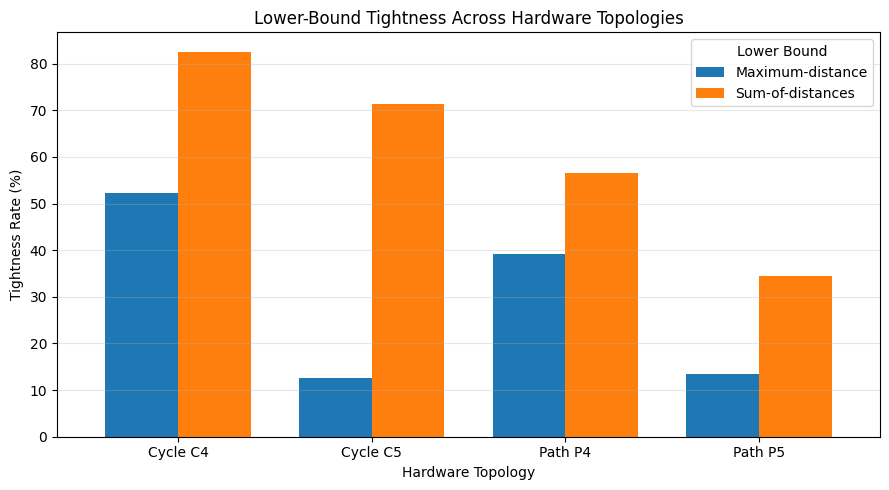

In [ ]:
import matplotlib.pyplot as plt

plot_data = nontrivial_comparison.pivot(
    index="Topology",
    columns="Lower Bound",
    values="Tightness (%)"
)

plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

plt.title("Lower-Bound Tightness Across Hardware Topologies")
plt.xlabel("Hardware Topology")
plt.ylabel("Tightness Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Lower Bound")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Average Lower-Bound Gap

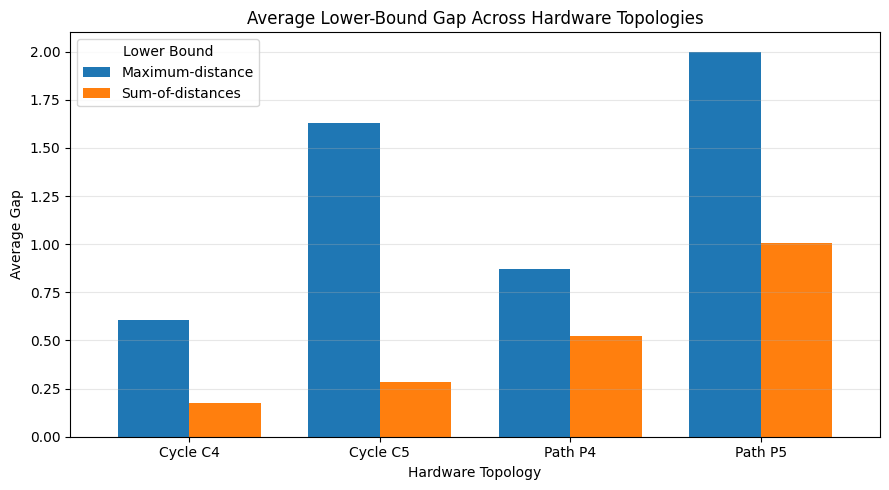

In [ ]:
gap_data = nontrivial_comparison.pivot(
    index="Topology",
    columns="Lower Bound",
    values="Average Gap"
)

gap_data.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75
)

plt.title("Average Lower-Bound Gap Across Hardware Topologies")
plt.xlabel("Hardware Topology")
plt.ylabel("Average Gap")
plt.xticks(rotation=0)
plt.legend(title="Lower Bound")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 3.8 Preliminary Analysis Across Topologies

The experimental results indicate that the sum-of-distances lower bound consistently outperforms the maximum-distance lower bound across all four tested hardware topologies.

In terms of tightness rate, the sum-of-distances lower bound achieves higher values for every topology. The most notable result occurs in Cycle C4, where its tightness rate reaches 82.61%.

The average-gap metric provides further evidence. The sum-of-distances lower bound consistently produces smaller average gaps than the maximum-distance lower bound.

A substantial difference is observed in Cycle C5, where the average gap decreases from 1.6303 to 0.2857.

These observations suggest that considering the collective displacement of logical qubits provides a more informative lower bound than considering only the maximum individual displacement in the tested instances.

However, these findings are preliminary and are limited to four small hardware topologies. They do not establish universal dominance of the sum-of-distances lower bound.

## 4. Mathematical Relationship Between the Two Lower Bounds

### 4.1 Investigating the Relationship Between the Two Lower Bounds

In [ ]:
def compare_lower_bounds(results, topology):

    sum_stronger = 0
    equal = 0
    max_stronger = 0

    for r in results:

        max_lb = r["max_bound"]
        sum_lb = r["sum_bound"]

        if sum_lb > max_lb:
            sum_stronger += 1

        elif sum_lb == max_lb:
            equal += 1

        else:
            max_stronger += 1

    print(f"\n{topology}")
    print("Sum-of-distances stronger:", sum_stronger)
    print("Both equal:", equal)
    print("Maximum-distance stronger:", max_stronger)

### 4.2 Computational Verification Across All Topologies

In [ ]:
compare_lower_bounds(results, "Path P4")

compare_lower_bounds(results_cycle, "Cycle C4")

compare_lower_bounds(results_path5, "Path P5")

compare_lower_bounds(results_cycle5, "Cycle C5")


Path P4
Sum-of-distances stronger: 7
Both equal: 17
Maximum-distance stronger: 0

Cycle C4
Sum-of-distances stronger: 9
Both equal: 15
Maximum-distance stronger: 0

Path P5
Sum-of-distances stronger: 77
Both equal: 43
Maximum-distance stronger: 0

Cycle C5
Sum-of-distances stronger: 99
Both equal: 21
Maximum-distance stronger: 0


### 4.3 Mathematical Proposition and Proof

**Proposition.** For any permutation of logical qubits on a connected hardware graph, the sum-of-distances lower bound is at least as strong as the maximum-distance lower bound:

$$
L_{\mathrm{sum}} \geq L_{\max}
$$

**Proof.**

Consider a permutation cycle containing a logical qubit whose initial and target positions are $a$ and $b$, respectively, with:

$$
d_G(a,b)=D
$$

The remaining mappings in this permutation cycle form a sequence of vertices connecting $b$ back to $a$.

By the triangle inequality, the sum of distances along this sequence is at least:

$$
d_G(b,a)=D
$$

Therefore, the total distance contributed by this permutation cycle is at least:

$$
D+D=2D
$$

Since all other contributions to the total distance are nonnegative:

$$
\sum_q d_G(p(q),t(q))\geq 2D
$$

Thus:

$$
L_{\mathrm{sum}}
=
\left\lceil
\frac{\sum_q d_G(p(q),t(q))}{2}
\right\rceil
\geq D
$$

Taking $D=L_{\max}$, we obtain:

$$
\boxed{L_{\mathrm{sum}}\geq L_{\max}}
$$



**Implication.** The sum-of-distances lower bound dominates the maximum-distance lower bound for every configuration under the considered model. The experimental comparison is consistent with this mathematical result.

### 4.4 Distribution of Lower-Bound Gaps

In [ ]:
def gap_distribution(results, topology):

    gap_counts = {}

    for r in results:
        gap = r["sum_gap"]

        gap_counts[gap] = gap_counts.get(gap, 0) + 1

    print(f"\n{topology}")
    print("Sum-of-distances gap distribution:")

    for gap in sorted(gap_counts):
        print(f"Gap {gap}: {gap_counts[gap]} configurations")

#### Evaluation Across All Tested Topologies

In [ ]:
gap_distribution(results, "Path P4")

gap_distribution(results_cycle, "Cycle C4")

gap_distribution(results_path5, "Path P5")

gap_distribution(results_cycle5, "Cycle C5")


Path P4
Sum-of-distances gap distribution:
Gap 0: 14 configurations
Gap 1: 8 configurations
Gap 2: 2 configurations

Cycle C4
Sum-of-distances gap distribution:
Gap 0: 20 configurations
Gap 1: 4 configurations

Path P5
Sum-of-distances gap distribution:
Gap 0: 42 configurations
Gap 1: 45 configurations
Gap 2: 25 configurations
Gap 3: 7 configurations
Gap 4: 1 configurations

Cycle C5
Sum-of-distances gap distribution:
Gap 0: 86 configurations
Gap 1: 34 configurations


## 5. Mathematical and Computational Validation

The two lower bounds are evaluated against exact optimal solutions obtained using Breadth-First Search (BFS).

For every tested configuration, the following conditions must hold:

### 1. Lower-Bound Validity

The lower bounds must never exceed the exact optimal SWAP cost.

$$
L_{\max} \leq C^*
$$

$$
L_{\mathrm{sum}} \leq C^*
$$

### 2. Dominance of the Sum-of-Distances Bound

The sum-of-distances lower bound must be at least as strong as the maximum-distance lower bound.

$$
L_{\mathrm{sum}} \geq L_{\max}
$$

The first condition ensures that neither lower bound overestimates the optimal SWAP cost. The second condition verifies the theoretical proposition established earlier.

These conditions are checked computationally across all tested configurations and hardware topologies.

In [ ]:
all_results = {
    "Path P4": results,
    "Cycle C4": results_cycle,
    "Path P5": results_path5,
    "Cycle C5": results_cycle5
}

for topology, results in all_results.items():

    valid_max = all(
        r["max_bound"] <= r["exact_optimal_cost"]
        for r in results
    )

    valid_sum = all(
        r["sum_bound"] <= r["exact_optimal_cost"]
        for r in results
    )

    dominance = all(
        r["sum_bound"] >= r["max_bound"]
        for r in results
    )

    print(f"\n{topology}")
    print("Maximum-distance valid:", valid_max)
    print("Sum-of-distances valid:", valid_sum)
    print("Sum bound dominates max bound:", dominance)


Path P4
Maximum-distance valid: True
Sum-of-distances valid: True
Sum bound dominates max bound: True

Cycle C4
Maximum-distance valid: True
Sum-of-distances valid: True
Sum bound dominates max bound: True

Path P5
Maximum-distance valid: True
Sum-of-distances valid: True
Sum bound dominates max bound: True

Cycle C5
Maximum-distance valid: True
Sum-of-distances valid: True
Sum bound dominates max bound: True


## 6. Greedy Heuristic Algorithm

The greedy heuristic selects the hardware SWAP operation that produces the greatest immediate reduction in the total distance between logical qubits and their target positions.

At each iteration, the algorithm evaluates all available SWAP operations and selects the one that minimizes the resulting total distance.

The algorithm terminates when the target configuration is reached or when no available SWAP produces a strict reduction in total distance.

This approach provides a simple baseline for studying the limitations of locally optimal decisions in quantum qubit routing.

In [ ]:
import networkx as nx

def total_distance(state, target, graph):
    total = 0

    for qubit in state:
        current_position = state.index(qubit)
        target_position = target.index(qubit)

        distance = nx.shortest_path_length(
            graph,
            current_position,
            target_position
        )

        total += distance

    return total


def greedy_routing(initial, target, graph):

    current_state = initial
    history = [current_state]
    moves = []

    while current_state != target:

        current_distance = total_distance(
            current_state, target, graph
        )

        best_distance = current_distance
        best_state = None
        best_move = None

        for u, v in graph.edges():

            candidate = list(current_state)

            candidate[u], candidate[v] = (
                candidate[v], candidate[u]
            )

            candidate = tuple(candidate)

            candidate_distance = total_distance(
                candidate, target, graph
            )

            if candidate_distance < best_distance:
                best_distance = candidate_distance
                best_state = candidate
                best_move = (u, v)

        if best_state is None:
            break

        current_state = best_state
        history.append(current_state)
        moves.append(best_move)

    return {
        "final_state": current_state,
        "moves": moves,
        "history": history,
        "success": current_state == target,
        "total_swaps": len(moves),
        "final_distance": total_distance(
            current_state, target, graph
        )
    }

### 6.1 Investigating Greedy Failure Cases

In [ ]:
G_test = nx.path_graph(4)

initial_test = ("A", "B", "C", "D")
target_test = ("D", "C", "B", "A")

greedy_result = greedy_routing(
    initial_test,
    target_test,
    G_test
)

print("Initial state:", initial_test)
print("Target state:", target_test)

print("\nGreedy result:")
print("Final state:", greedy_result["final_state"])
print("Moves:", greedy_result["moves"])
print("Total SWAPs:", greedy_result["total_swaps"])
print("Success:", greedy_result["success"])
print("Final distance:", greedy_result["final_distance"])

Initial state: ('A', 'B', 'C', 'D')
Target state: ('D', 'C', 'B', 'A')

Greedy result:
Final state: ('A', 'C', 'B', 'D')
Moves: [(1, 2)]
Total SWAPs: 1
Success: False
Final distance: 6


In [ ]:
# Analyze the local minimum state

trapped_state = greedy_result["final_state"]

current_distance = total_distance(
    trapped_state,
    target_test,
    G_test
)

print("Trapped state:", trapped_state)
print("Current distance:", current_distance)
print("\nPossible SWAP operations:")

for u, v in G_test.edges():

    candidate = list(trapped_state)

    candidate[u], candidate[v] = (
        candidate[v],
        candidate[u]
    )

    candidate = tuple(candidate)

    candidate_distance = total_distance(
        candidate,
        target_test,
        G_test
    )

    print(
        f"SWAP ({u}, {v}) -> {candidate}",
        f"| Distance: {candidate_distance}",
        f"| Improvement: {candidate_distance < current_distance}"
    )

Trapped state: ('A', 'C', 'B', 'D')
Current distance: 6

Possible SWAP operations:
SWAP (0, 1) -> ('C', 'A', 'B', 'D') | Distance: 6 | Improvement: False
SWAP (1, 2) -> ('A', 'B', 'C', 'D') | Distance: 8 | Improvement: False
SWAP (2, 3) -> ('A', 'C', 'D', 'B') | Distance: 6 | Improvement: False


### 6.2 Analysis: Greedy Algorithm and Local Minima

The greedy routing algorithm fails to reach the target configuration in the reversal instance on the path graph P4.

After performing SWAP (1,2), the total distance decreases from 8 to 6. However, none of the available neighboring SWAP operations produces a strictly lower distance.

The candidate distances are:

- SWAP (0,1): 6
- SWAP (1,2): 8
- SWAP (2,3): 6

Consequently, the greedy algorithm terminates at a local minimum, even though the target configuration has not been reached.

In contrast, the exact BFS solver finds an optimal solution using six SWAP operations.

This demonstrates a limitation of strict greedy optimization: locally non-improving moves may be necessary to reach a globally optimal solution.

**Observation:** A heuristic based solely on immediate distance reduction may become trapped in a local minimum and fail to complete the routing task.

### 6.3 Systematic Evaluation: BFS vs Greedy on Path P4

#### Objective

This experiment evaluates the performance of a greedy routing heuristic against an exact BFS solver across all 24 possible target configurations on a Path P4 hardware topology.

The initial configuration is fixed as ABCD, while every permutation of the four logical qubits is used as a target.

#### Evaluation Metrics

1. **BFS Optimal Cost:** The minimum number of SWAP operations obtained through exact breadth-first search.
2. **Greedy Success Rate:** The proportion of target configurations successfully reached by the greedy algorithm.
3. **Greedy SWAP Count:** The number of SWAP operations performed by the heuristic.
4. **Optimality Gap:** The difference between the greedy SWAP count and the BFS optimal cost, calculated only for successful greedy runs.

#### Research Objective

To determine whether the greedy heuristic can consistently find optimal routing solutions and to characterize its failure cases across the complete configuration space of Path P4.

#### Automatic Evaluation

In [ ]:
from collections import deque
from itertools import permutations

# Exact BFS solver
def exact_bfs(initial, target, graph):

    queue = deque([(initial, 0)])
    visited = {initial}

    while queue:

        state, cost = queue.popleft()

        if state == target:
            return cost

        for u, v in graph.edges():

            candidate = list(state)
            candidate[u], candidate[v] = (
                candidate[v], candidate[u]
            )

            candidate = tuple(candidate)

            if candidate not in visited:
                visited.add(candidate)
                queue.append((candidate, cost + 1))

    return None


# Define Path P4
G_P4 = nx.path_graph(4)

# Initial configuration
initial = ("A", "B", "C", "D")

# Generate all 24 target configurations
all_targets = list(permutations(initial))

# Store experimental results
results = []

for target in all_targets:

    # Exact optimal cost
    bfs_cost = exact_bfs(
        initial,
        target,
        G_P4
    )

    # Greedy result
    greedy_result = greedy_routing(
        initial,
        target,
        G_P4
    )

    # Calculate optimality gap
    if greedy_result["success"]:
        gap = (
            greedy_result["total_swaps"] - bfs_cost
        )
    else:
        gap = None

    results.append({
        "target": target,
        "bfs_cost": bfs_cost,
        "greedy_success": greedy_result["success"],
        "greedy_swaps": greedy_result["total_swaps"],
        "optimality_gap": gap
    })


print("Total configurations:", len(results))
print("\nDetailed Results:")

for result in results:
    print(
        result["target"],
        "| BFS:", result["bfs_cost"],
        "| Greedy success:", result["greedy_success"],
        "| Greedy SWAPs:", result["greedy_swaps"],
        "| Gap:", result["optimality_gap"]
    )

Total configurations: 24

Detailed Results:
('A', 'B', 'C', 'D') | BFS: 0 | Greedy success: True | Greedy SWAPs: 0 | Gap: 0
('A', 'B', 'D', 'C') | BFS: 1 | Greedy success: True | Greedy SWAPs: 1 | Gap: 0
('A', 'C', 'B', 'D') | BFS: 1 | Greedy success: True | Greedy SWAPs: 1 | Gap: 0
('A', 'C', 'D', 'B') | BFS: 2 | Greedy success: True | Greedy SWAPs: 2 | Gap: 0
('A', 'D', 'B', 'C') | BFS: 2 | Greedy success: True | Greedy SWAPs: 2 | Gap: 0
('A', 'D', 'C', 'B') | BFS: 3 | Greedy success: False | Greedy SWAPs: 0 | Gap: None
('B', 'A', 'C', 'D') | BFS: 1 | Greedy success: True | Greedy SWAPs: 1 | Gap: 0
('B', 'A', 'D', 'C') | BFS: 2 | Greedy success: True | Greedy SWAPs: 2 | Gap: 0
('B', 'C', 'A', 'D') | BFS: 2 | Greedy success: True | Greedy SWAPs: 2 | Gap: 0
('B', 'C', 'D', 'A') | BFS: 3 | Greedy success: True | Greedy SWAPs: 3 | Gap: 0
('B', 'D', 'A', 'C') | BFS: 3 | Greedy success: True | Greedy SWAPs: 3 | Gap: 0
('B', 'D', 'C', 'A') | BFS: 4 | Greedy success: False | Greedy SWAPs: 1 

#### Summary of Greedy Performance

In [ ]:
total = len(results)

successes = sum(
    result["greedy_success"]
    for result in results
)

failures = total - successes

successful_runs = [
    result for result in results
    if result["greedy_success"]
]

optimal_runs = sum(
    result["optimality_gap"] == 0
    for result in successful_runs
)

print("=== EXPERIMENT SUMMARY ===")
print("Total configurations:", total)
print("Successful runs:", successes)
print("Failed runs:", failures)

print(
    "Success rate:",
    round(successes / total * 100, 2), "%"
)

print(
    "Failure rate:",
    round(failures / total * 100, 2), "%"
)

print("Optimal solutions among successful runs:", optimal_runs)

print(
    "Optimality rate among successful runs:",
    round(optimal_runs / successes * 100, 2), "%"
)

=== EXPERIMENT SUMMARY ===
Total configurations: 24
Successful runs: 14
Failed runs: 10
Success rate: 58.33 %
Failure rate: 41.67 %
Optimal solutions among successful runs: 14
Optimality rate among successful runs: 100.0 %


#### Analysis of Failed Routing Instances

In [ ]:
print("=== FAILURE ANALYSIS ===")

for result in results:

    if not result["greedy_success"]:

        target = result["target"]

        greedy_result = greedy_routing(
            initial,
            target,
            G_P4
        )

        stuck_state = greedy_result["final_state"]

        current_distance = total_distance(
            stuck_state,
            target,
            G_P4
        )

        candidate_distances = []

        for u, v in G_P4.edges():

            candidate = list(stuck_state)

            candidate[u], candidate[v] = (
                candidate[v], candidate[u]
            )

            candidate = tuple(candidate)

            candidate_distance = total_distance(
                candidate,
                target,
                G_P4
            )

            candidate_distances.append(
                candidate_distance
            )

        best_neighbor_distance = min(
            candidate_distances
        )

        if best_neighbor_distance == current_distance:
            classification = "PLATEAU EXISTS"

        else:
            classification = "STRICT LOCAL MINIMUM"

        print("\nTarget:", target)
        print("Stuck state:", stuck_state)
        print("Current distance:", current_distance)
        print("Neighbor distances:", candidate_distances)
        print("Best neighbor distance:", best_neighbor_distance)
        print("Classification:", classification)

=== FAILURE ANALYSIS ===

Target: ('A', 'D', 'C', 'B')
Stuck state: ('A', 'B', 'C', 'D')
Current distance: 4
Neighbor distances: [6, 4, 4]
Best neighbor distance: 4
Classification: PLATEAU EXISTS

Target: ('B', 'D', 'C', 'A')
Stuck state: ('B', 'A', 'C', 'D')
Current distance: 4
Neighbor distances: [6, 4, 4]
Best neighbor distance: 4
Classification: PLATEAU EXISTS

Target: ('C', 'B', 'A', 'D')
Stuck state: ('A', 'B', 'C', 'D')
Current distance: 4
Neighbor distances: [4, 4, 6]
Best neighbor distance: 4
Classification: PLATEAU EXISTS

Target: ('C', 'B', 'D', 'A')
Stuck state: ('A', 'B', 'C', 'D')
Current distance: 6
Neighbor distances: [6, 6, 6]
Best neighbor distance: 6
Classification: PLATEAU EXISTS

Target: ('C', 'D', 'B', 'A')
Stuck state: ('C', 'A', 'B', 'D')
Current distance: 4
Neighbor distances: [6, 4, 4]
Best neighbor distance: 4
Classification: PLATEAU EXISTS

Target: ('D', 'A', 'C', 'B')
Stuck state: ('A', 'B', 'C', 'D')
Current distance: 6
Neighbor distances: [6, 6, 6]
Best n

## 7. Plateau-Aware Greedy Heuristic

In [ ]:
def plateau_greedy_routing(initial, target, graph):

    current_state = initial
    history = [current_state]
    moves = []

    visited_states = {current_state}

    while current_state != target:

        current_distance = total_distance(
            current_state,
            target,
            graph
        )

        candidates = []

        for u, v in graph.edges():

            candidate = list(current_state)

            candidate[u], candidate[v] = (
                candidate[v], candidate[u]
            )

            candidate = tuple(candidate)

            # Avoid revisiting states
            if candidate in visited_states:
                continue

            candidate_distance = total_distance(
                candidate,
                target,
                graph
            )

            # Accept improving or equal-distance moves
            if candidate_distance <= current_distance:

                candidates.append(
                    (candidate_distance, candidate, (u, v))
                )

        # No acceptable unvisited neighbor
        if not candidates:
            break

        # Choose the neighbor with the lowest distance
        best_distance, best_state, best_move = min(
            candidates,
            key=lambda x: x[0]
        )

        current_state = best_state

        visited_states.add(current_state)
        history.append(current_state)
        moves.append(best_move)

    return {
        "final_state": current_state,
        "moves": moves,
        "history": history,
        "success": current_state == target,
        "total_swaps": len(moves),
        "final_distance": total_distance(
            current_state,
            target,
            graph
        )
    }

### 7.1 Demonstration on a Single Instances

In [ ]:
initial_test = ("A", "B", "C", "D")
target_test = ("D", "C", "B", "A")

plateau_result = plateau_greedy_routing(
    initial_test,
    target_test,
    G_P4
)

print("Initial state:", initial_test)
print("Target state:", target_test)

print("\nPlateau-aware Greedy result:")
print("Final state:", plateau_result["final_state"])
print("Moves:", plateau_result["moves"])
print("Total SWAPs:", plateau_result["total_swaps"])
print("Success:", plateau_result["success"])
print("Final distance:", plateau_result["final_distance"])

Initial state: ('A', 'B', 'C', 'D')
Target state: ('D', 'C', 'B', 'A')

Plateau-aware Greedy result:
Final state: ('D', 'C', 'B', 'A')
Moves: [(1, 2), (0, 1), (1, 2), (2, 3), (1, 2), (0, 1)]
Total SWAPs: 6
Success: True
Final distance: 0


### 7.2 Evaluation Across All P4 Target Configurations

In [ ]:
plateau_results = []

for target in all_targets:

    bfs_cost = exact_bfs(
        initial,
        target,
        G_P4
    )

    result = plateau_greedy_routing(
        initial,
        target,
        G_P4
    )

    if result["success"]:
        gap = result["total_swaps"] - bfs_cost
    else:
        gap = None

    plateau_results.append({
        "target": target,
        "bfs_cost": bfs_cost,
        "success": result["success"],
        "greedy_swaps": result["total_swaps"],
        "optimality_gap": gap
    })


successes = sum(
    r["success"] for r in plateau_results
)

failures = len(plateau_results) - successes

optimal = sum(
    r["optimality_gap"] == 0
    for r in plateau_results
    if r["success"]
)

print("=== PLATEAU-AWARE GREEDY SUMMARY ===")
print("Total configurations:", len(plateau_results))
print("Successful runs:", successes)
print("Failed runs:", failures)

print(
    "Success rate:",
    round(successes / len(plateau_results) * 100, 2),
    "%"
)

print("Optimal solutions:", optimal)

print(
    "Optimality rate among successful runs:",
    round(optimal / successes * 100, 2) if successes else 0,
    "%"
)

=== PLATEAU-AWARE GREEDY SUMMARY ===
Total configurations: 24
Successful runs: 24
Failed runs: 0
Success rate: 100.0 %
Optimal solutions: 23
Optimality rate among successful runs: 95.83 %


### 7.3 Identification of Suboptimal Solutions

In [ ]:
print("=== SUBOPTIMAL CASES ===")

for r in plateau_results:

    if r["success"] and r["optimality_gap"] > 0:

        print("\nTarget:", r["target"])
        print("BFS optimal cost:", r["bfs_cost"])
        print("Plateau-aware SWAPs:", r["greedy_swaps"])
        print("Optimality gap:", r["optimality_gap"])

=== SUBOPTIMAL CASES ===

Target: ('D', 'A', 'C', 'B')
BFS optimal cost: 4
Plateau-aware SWAPs: 6
Optimality gap: 2


### 7.4 Analysis of the Optimality Gap

In [ ]:
from collections import deque

def bfs_route(initial, target, graph):
    queue = deque([initial])
    parent = {initial: None}
    move_used = {}

    while queue:
        state = queue.popleft()

        if state == target:
            break

        for u, v in graph.edges():
            new_state = list(state)
            new_state[u], new_state[v] = new_state[v], new_state[u]
            new_state = tuple(new_state)

            if new_state not in parent:
                parent[new_state] = state
                move_used[new_state] = (u, v)
                queue.append(new_state)

    if target not in parent:
        return None, None

    route = []
    moves = []
    current = target

    while current is not None:
        route.append(current)

        if parent[current] is not None:
            moves.append(move_used[current])

        current = parent[current]

    route.reverse()
    moves.reverse()

    return route, moves


initial = ("A", "B", "C", "D")
target = ("D", "A", "C", "B")

# Plateau-aware Greedy
greedy_result = plateau_greedy_routing(
    initial, target, G_P4
)

# Exact BFS
optimal_route, optimal_moves = bfs_route(
    initial, target, G_P4
)

print("=== PLATEAU-AWARE GREEDY ===")
print("States:")
for i, state in enumerate(greedy_result["history"]):
    print(i, state, "| distance:",
          total_distance(state, target, G_P4))

print("Moves:", greedy_result["moves"])
print("Total SWAPs:", greedy_result["total_swaps"])

print("\n=== EXACT BFS ===")
print("States:")
for i, state in enumerate(optimal_route):
    print(i, state, "| distance:",
          total_distance(state, target, G_P4))

print("Moves:", optimal_moves)
print("Total SWAPs:", len(optimal_moves))

=== PLATEAU-AWARE GREEDY ===
States:
0 ('A', 'B', 'C', 'D') | distance: 6
1 ('B', 'A', 'C', 'D') | distance: 6
2 ('B', 'A', 'D', 'C') | distance: 6
3 ('A', 'B', 'D', 'C') | distance: 6
4 ('A', 'D', 'B', 'C') | distance: 4
5 ('D', 'A', 'B', 'C') | distance: 2
6 ('D', 'A', 'C', 'B') | distance: 0
Moves: [(0, 1), (2, 3), (0, 1), (1, 2), (0, 1), (2, 3)]
Total SWAPs: 6

=== EXACT BFS ===
States:
0 ('A', 'B', 'C', 'D') | distance: 6
1 ('A', 'C', 'B', 'D') | distance: 6
2 ('A', 'C', 'D', 'B') | distance: 4
3 ('A', 'D', 'C', 'B') | distance: 2
4 ('D', 'A', 'C', 'B') | distance: 0
Moves: [(1, 2), (2, 3), (1, 2), (0, 1)]
Total SWAPs: 4


### 7.5 Tie-Breaking Analysis

In [ ]:
print("=== INITIAL STATE: TIE-BREAKING ANALYSIS ===")

state = ("A", "B", "C", "D")
target = ("D", "A", "C", "B")

current_distance = total_distance(state, target, G_P4)

print("Current state:", state)
print("Current distance:", current_distance)

for u, v in G_P4.edges():
    new_state = list(state)
    new_state[u], new_state[v] = new_state[v], new_state[u]
    new_state = tuple(new_state)

    distance = total_distance(new_state, target, G_P4)

    print(
        f"SWAP {(u,v)} -> {new_state}, "
        f"distance = {distance}"
    )

=== INITIAL STATE: TIE-BREAKING ANALYSIS ===
Current state: ('A', 'B', 'C', 'D')
Current distance: 6
SWAP (0, 1) -> ('B', 'A', 'C', 'D'), distance = 6
SWAP (1, 2) -> ('A', 'C', 'B', 'D'), distance = 6
SWAP (2, 3) -> ('A', 'B', 'D', 'C'), distance = 6


## 8. One-Step Lookahead Heuristic

In [ ]:
print("=== TWO-STEP LOOKAHEAD ANALYSIS ===")

initial = ("A", "B", "C", "D")
target = ("D", "A", "C", "B")

for u1, v1 in G_P4.edges():

    # First SWAP
    state1 = list(initial)
    state1[u1], state1[v1] = state1[v1], state1[u1]
    state1 = tuple(state1)

    first_distance = total_distance(state1, target, G_P4)

    second_candidates = []

    for u2, v2 in G_P4.edges():

        state2 = list(state1)
        state2[u2], state2[v2] = state2[v2], state2[u2]
        state2 = tuple(state2)

        # Exclude returning to the initial state
        if state2 == initial:
            continue

        second_distance = total_distance(
            state2, target, G_P4
        )

        second_candidates.append({
            "move": (u2, v2),
            "state": state2,
            "distance": second_distance
        })

    best_second = min(
        second_candidates,
        key=lambda x: x["distance"]
    )

    print("\nFirst SWAP:", (u1, v1))
    print("State after first SWAP:", state1)
    print("Distance after first SWAP:", first_distance)
    print("Best second SWAP:", best_second["move"])
    print("State after second SWAP:", best_second["state"])
    print("Distance after second SWAP:", best_second["distance"])

=== TWO-STEP LOOKAHEAD ANALYSIS ===

First SWAP: (0, 1)
State after first SWAP: ('B', 'A', 'C', 'D')
Distance after first SWAP: 6
Best second SWAP: (2, 3)
State after second SWAP: ('B', 'A', 'D', 'C')
Distance after second SWAP: 6

First SWAP: (1, 2)
State after first SWAP: ('A', 'C', 'B', 'D')
Distance after first SWAP: 6
Best second SWAP: (2, 3)
State after second SWAP: ('A', 'C', 'D', 'B')
Distance after second SWAP: 4

First SWAP: (2, 3)
State after first SWAP: ('A', 'B', 'D', 'C')
Distance after first SWAP: 6
Best second SWAP: (1, 2)
State after second SWAP: ('A', 'D', 'B', 'C')
Distance after second SWAP: 4


### 8.1 Algorithm Construction

In [ ]:
def lookahead_greedy_routing(initial, target, graph):
    current = initial
    moves = []
    history = [current]
    visited = {current}

    while current != target:

        current_distance = total_distance(
            current, target, graph
        )

        candidates = []

        for u, v in graph.edges():

            # Simulate first SWAP
            state1 = list(current)
            state1[u], state1[v] = state1[v], state1[u]
            state1 = tuple(state1)

            if state1 in visited:
                continue

            distance1 = total_distance(
                state1, target, graph
            )

            # Find the best possible second SWAP
            second_distances = []

            for x, y in graph.edges():

                state2 = list(state1)
                state2[x], state2[y] = state2[y], state2[x]
                state2 = tuple(state2)

                if state2 in visited or state2 == current:
                    continue

                distance2 = total_distance(
                    state2, target, graph
                )

                second_distances.append(distance2)

            if second_distances:
                best_second_distance = min(second_distances)
            else:
                best_second_distance = distance1

            candidates.append((
                best_second_distance,
                distance1,
                (u, v),
                state1
            ))

        if not candidates:
            break

        # Prioritize two-step score, then one-step score
        candidates.sort(key=lambda x: (x[0], x[1]))

        best = candidates[0]
        next_state = best[3]

        # Prevent non-improving infinite exploration
        if best[0] > current_distance and best[1] >= current_distance:
            break

        moves.append(best[2])
        current = next_state
        history.append(current)
        visited.add(current)

    return {
        "final_state": current,
        "moves": moves,
        "history": history,
        "success": current == target,
        "total_swaps": len(moves),
        "final_distance": total_distance(current, target, graph)
    }

### 8.2 Single-Instance Evaluation

In [ ]:
initial = ("A", "B", "C", "D")
target = ("D", "A", "C", "B")

lookahead_result = lookahead_greedy_routing(
    initial, target, G_P4
)

print("=== LOOKAHEAD GREEDY ===")

for i, state in enumerate(lookahead_result["history"]):
    print(
        i, state,
        "| distance:",
        total_distance(state, target, G_P4)
    )

print("Moves:", lookahead_result["moves"])
print("Success:", lookahead_result["success"])
print("Total SWAPs:", lookahead_result["total_swaps"])

=== LOOKAHEAD GREEDY ===
0 ('A', 'B', 'C', 'D') | distance: 6
1 ('A', 'C', 'B', 'D') | distance: 6
2 ('A', 'C', 'D', 'B') | distance: 4
3 ('A', 'D', 'C', 'B') | distance: 2
4 ('D', 'A', 'C', 'B') | distance: 0
Moves: [(1, 2), (2, 3), (1, 2), (0, 1)]
Success: True
Total SWAPs: 4


### 8.3 Evaluation Across All P4 Target Configurations

In [ ]:
lookahead_results = []

for target in all_targets:
    result = lookahead_greedy_routing(
        initial, target, G_P4
    )

    bfs_cost = exact_bfs(initial, target, G_P4)

    lookahead_results.append({
        "target": target,
        "bfs_cost": bfs_cost,
        "lookahead_success": result["success"],
        "lookahead_swaps": result["total_swaps"],
        "optimality_gap": (
            result["total_swaps"] - bfs_cost
            if result["success"] else None
        )
    })

total = len(lookahead_results)
successes = sum(
    r["lookahead_success"] for r in lookahead_results
)

optimal = sum(
    r["lookahead_success"] and r["optimality_gap"] == 0
    for r in lookahead_results
)

print("=== LOOKAHEAD GREEDY: P4 EVALUATION ===")
print("Total targets:", total)
print("Successful:", successes)
print("Failed:", total - successes)
print("Success rate:", round(successes / total * 100, 2), "%")
print("Optimal solutions:", optimal)
print("Optimality rate:", round(optimal / total * 100, 2), "%")

print("\n=== SUBOPTIMAL OR FAILED CASES ===")

for r in lookahead_results:
    if not r["lookahead_success"] or r["optimality_gap"] > 0:
        print(r)

=== LOOKAHEAD GREEDY: P4 EVALUATION ===
Total targets: 24
Successful: 24
Failed: 0
Success rate: 100.0 %
Optimal solutions: 24
Optimality rate: 100.0 %

=== SUBOPTIMAL OR FAILED CASES ===


### 8.4 Evaluation on P5 and C5

In [ ]:
from itertools import permutations
import networkx as nx

def evaluate_lookahead(graph, initial):
    targets = list(permutations(initial))
    results = []

    for target in targets:
        result = lookahead_greedy_routing(
            initial, target, graph
        )

        bfs_cost = exact_bfs(
            initial, target, graph
        )

        gap = (
            result["total_swaps"] - bfs_cost
            if result["success"] else None
        )

        results.append({
            "target": target,
            "bfs_cost": bfs_cost,
            "success": result["success"],
            "lookahead_swaps": result["total_swaps"],
            "optimality_gap": gap
        })

    total = len(results)
    successful = sum(r["success"] for r in results)
    optimal = sum(
        r["success"] and r["optimality_gap"] == 0
        for r in results
    )

    return {
        "results": results,
        "total": total,
        "successful": successful,
        "failed": total - successful,
        "success_rate": successful / total * 100,
        "optimal": optimal,
        "optimality_rate": optimal / total * 100
    }


# P5
G_P5 = nx.path_graph(5)
initial_P5 = ("A", "B", "C", "D", "E")

p5_evaluation = evaluate_lookahead(
    G_P5, initial_P5
)

# C5
G_C5 = nx.cycle_graph(5)
initial_C5 = ("A", "B", "C", "D", "E")

c5_evaluation = evaluate_lookahead(
    G_C5, initial_C5
)


for name, evaluation in [
    ("P5", p5_evaluation),
    ("C5", c5_evaluation)
]:
    print(f"\n=== {name} RESULTS ===")
    print("Total:", evaluation["total"])
    print("Successful:", evaluation["successful"])
    print("Failed:", evaluation["failed"])
    print("Success rate:", round(evaluation["success_rate"], 2), "%")
    print("Optimal:", evaluation["optimal"])
    print("Optimality rate:", round(evaluation["optimality_rate"], 2), "%")

    print("\nSuboptimal or failed cases:")
    for r in evaluation["results"]:
        if not r["success"] or r["optimality_gap"] > 0:
            print(r)


=== P5 RESULTS ===
Total: 120
Successful: 120
Failed: 0
Success rate: 100.0 %
Optimal: 118
Optimality rate: 98.33 %

Suboptimal or failed cases:
{'target': ('E', 'A', 'C', 'D', 'B'), 'bfs_cost': 6, 'success': True, 'lookahead_swaps': 8, 'optimality_gap': 2}
{'target': ('E', 'A', 'D', 'C', 'B'), 'bfs_cost': 7, 'success': True, 'lookahead_swaps': 9, 'optimality_gap': 2}

=== C5 RESULTS ===
Total: 120
Successful: 120
Failed: 0
Success rate: 100.0 %
Optimal: 120
Optimality rate: 100.0 %

Suboptimal or failed cases:


### 8.5 Comparison of Heuristic

In [ ]:
counterexamples = [
    ("E", "A", "C", "D", "B"),
    ("E", "A", "D", "C", "B")
]

for target in counterexamples:

    print("\n" + "=" * 55)
    print("TARGET:", target)

    # Lookahead
    greedy = lookahead_greedy_routing(
        initial_P5, target, G_P5
    )

    # Exact BFS
    bfs_path, bfs_moves = bfs_route(
        initial_P5, target, G_P5
    )

    print("\n--- LOOKAHEAD GREEDY ---")

    for i, state in enumerate(greedy["history"]):
        print(
            i, state,
            "| distance:",
            total_distance(state, target, G_P5)
        )

    print("Moves:", greedy["moves"])
    print("Total SWAPs:", greedy["total_swaps"])

    print("\n--- EXACT BFS ---")

    for i, state in enumerate(bfs_path):
        print(
            i, state,
            "| distance:",
            total_distance(state, target, G_P5)
        )

    print("Moves:", bfs_moves)
    print("Total SWAPs:", len(bfs_moves))


TARGET: ('E', 'A', 'C', 'D', 'B')

--- LOOKAHEAD GREEDY ---
0 ('A', 'B', 'C', 'D', 'E') | distance: 8
1 ('B', 'A', 'C', 'D', 'E') | distance: 8
2 ('B', 'A', 'C', 'E', 'D') | distance: 8
3 ('A', 'B', 'C', 'E', 'D') | distance: 8
4 ('A', 'C', 'B', 'E', 'D') | distance: 8
5 ('A', 'C', 'E', 'B', 'D') | distance: 6
6 ('A', 'E', 'C', 'B', 'D') | distance: 4
7 ('E', 'A', 'C', 'B', 'D') | distance: 2
8 ('E', 'A', 'C', 'D', 'B') | distance: 0
Moves: [(0, 1), (3, 4), (0, 1), (1, 2), (2, 3), (1, 2), (0, 1), (3, 4)]
Total SWAPs: 8

--- EXACT BFS ---
0 ('A', 'B', 'C', 'D', 'E') | distance: 8
1 ('A', 'C', 'B', 'D', 'E') | distance: 8
2 ('A', 'C', 'D', 'B', 'E') | distance: 8
3 ('A', 'C', 'D', 'E', 'B') | distance: 6
4 ('A', 'C', 'E', 'D', 'B') | distance: 4
5 ('A', 'E', 'C', 'D', 'B') | distance: 2
6 ('E', 'A', 'C', 'D', 'B') | distance: 0
Moves: [(1, 2), (2, 3), (3, 4), (2, 3), (1, 2), (0, 1)]
Total SWAPs: 6

TARGET: ('E', 'A', 'D', 'C', 'B')

--- LOOKAHEAD GREEDY ---
0 ('A', 'B', 'C', 'D', 'E') |

## 9. Multi-Step Lookahead Heuristic

In [ ]:
def lookahead_k_routing(initial, target, graph, depth=3):
    current = initial
    history = [current]
    moves = []
    visited = {current}

    while current != target:
        candidates = []

        def explore(state, path_states, path_moves, remaining):
            if remaining == 0:
                distances = [
                    total_distance(s, target, graph)
                    for s in path_states
                ]

                # Prefer lower final distance,
                # then lower intermediate distances.
                score = tuple(reversed(distances))

                candidates.append((
                    score,
                    path_moves[0],
                    path_states[0]
                ))
                return

            for u, v in graph.edges():
                new_state = list(state)
                new_state[u], new_state[v] = (
                    new_state[v], new_state[u]
                )
                new_state = tuple(new_state)

                if new_state in visited or new_state in path_states:
                    continue

                explore(
                    new_state,
                    path_states + [new_state],
                    path_moves + [(u, v)],
                    remaining - 1
                )

        explore(current, [], [], depth)

        if not candidates:
            break

        candidates.sort(key=lambda x: x[0])
        best = candidates[0]

        next_state = best[2]

        moves.append(best[1])
        current = next_state
        history.append(current)
        visited.add(current)

    return {
        "final_state": current,
        "history": history,
        "moves": moves,
        "success": current == target,
        "total_swaps": len(moves),
        "final_distance": total_distance(current, target, graph)
    }

### 9.1 Counterexample Analysis

In [ ]:
for target in counterexamples:
    result = lookahead_k_routing(
        initial_P5,
        target,
        G_P5,
        depth=3
    )

    print("\nTarget:", target)
    print("Success:", result["success"])
    print("SWAPs:", result["total_swaps"])
    print("BFS optimal:", exact_bfs(
        initial_P5, target, G_P5
    ))
    print("Optimality gap:",
          result["total_swaps"] - exact_bfs(
              initial_P5, target, G_P5
          ))
    print("Moves:", result["moves"])


Target: ('E', 'A', 'C', 'D', 'B')
Success: True
SWAPs: 8
BFS optimal: 6
Optimality gap: 2
Moves: [(1, 2), (2, 3), (3, 4), (2, 3), (1, 2), (2, 3), (0, 1), (2, 3)]

Target: ('E', 'A', 'D', 'C', 'B')
Success: True
SWAPs: 9
BFS optimal: 7
Optimality gap: 2
Moves: [(1, 2), (2, 3), (3, 4), (1, 2), (2, 3), (1, 2), (2, 3), (0, 1), (2, 3)]


### 9.2 Automated Evaluation

In [ ]:
def evaluate_lookahead_depth(graph, initial, depth):
    targets = list(permutations(initial))
    results = []

    for target in targets:
        result = lookahead_k_routing(
            initial, target, graph, depth=depth
        )

        optimal_cost = exact_bfs(
            initial, target, graph
        )

        results.append({
            "target": target,
            "success": result["success"],
            "swaps": result["total_swaps"],
            "optimal_cost": optimal_cost,
            "gap": (
                result["total_swaps"] - optimal_cost
                if result["success"] else None
            )
        })

    total = len(results)
    successful = sum(r["success"] for r in results)
    optimal = sum(
        r["success"] and r["gap"] == 0
        for r in results
    )

    return {
        "depth": depth,
        "success_rate": successful / total * 100,
        "optimality_rate": optimal / total * 100,
        "failed": total - successful,
        "suboptimal": sum(
            r["success"] and r["gap"] > 0
            for r in results
        ),
        "results": results
    }


depth_experiments = {}

for graph_name, graph, initial_state in [
    ("P5", G_P5, initial_P5),
    ("C5", G_C5, initial_C5)
]:
    for depth in [1, 2, 3]:
        evaluation = evaluate_lookahead_depth(
            graph, initial_state, depth
        )

        depth_experiments[(graph_name, depth)] = evaluation

        print(
            f"{graph_name} | Depth {depth} | "
            f"Success: {evaluation['success_rate']:.2f}% | "
            f"Optimality: {evaluation['optimality_rate']:.2f}% | "
            f"Failed: {evaluation['failed']} | "
            f"Suboptimal: {evaluation['suboptimal']}"
        )

P5 | Depth 1 | Success: 100.00% | Optimality: 82.50% | Failed: 0 | Suboptimal: 21
P5 | Depth 2 | Success: 100.00% | Optimality: 98.33% | Failed: 0 | Suboptimal: 2
P5 | Depth 3 | Success: 53.33% | Optimality: 5.83% | Failed: 56 | Suboptimal: 57
C5 | Depth 1 | Success: 100.00% | Optimality: 100.00% | Failed: 0 | Suboptimal: 0
C5 | Depth 2 | Success: 100.00% | Optimality: 100.00% | Failed: 0 | Suboptimal: 0
C5 | Depth 3 | Success: 0.83% | Optimality: 0.83% | Failed: 119 | Suboptimal: 0


## 10. Bounded-Depth Search and Distance-Based Evaluation

In [ ]:
def bounded_distance(state, target, graph, max_depth):
    """
    Find the minimum total-distance value reachable
    within at most max_depth SWAPs.
    """
    from collections import deque

    queue = deque([(state, 0)])
    visited = {state}

    best_distance = total_distance(state, target, graph)

    while queue:
        current, depth = queue.popleft()

        if current == target:
            return 0

        if depth == max_depth:
            continue

        for u, v in graph.edges():
            new_state = list(current)
            new_state[u], new_state[v] = new_state[v], new_state[u]
            new_state = tuple(new_state)

            if new_state in visited:
                continue

            visited.add(new_state)

            distance = total_distance(new_state, target, graph)
            best_distance = min(best_distance, distance)

            queue.append((new_state, depth + 1))

    return best_distance


def efficient_lookahead_routing(initial, target, graph, depth=2):
    current = tuple(initial)
    target = tuple(target)

    history = [current]
    moves = []
    visited = {current}

    while current != target:
        candidates = []

        for u, v in graph.edges():
            new_state = list(current)
            new_state[u], new_state[v] = new_state[v], new_state[u]
            new_state = tuple(new_state)

            if new_state in visited:
                continue

            future_distance = bounded_distance(
                new_state, target, graph, depth - 1
            )

            candidates.append(
                (future_distance, total_distance(new_state, target, graph),
                 (u, v), new_state)
            )

        if not candidates:
            break

        candidates.sort(key=lambda x: (x[0], x[1]))

        _, _, best_move, next_state = candidates[0]

        moves.append(best_move)
        current = next_state
        history.append(current)
        visited.add(current)

    return {
        "final_state": current,
        "moves": moves,
        "history": history,
        "success": current == target,
        "total_swaps": len(moves),
        "final_distance": total_distance(current, target, graph)
    }

In [ ]:
def total_distance(state, target, graph):
    total = 0

    for qubit in state:
        current_position = state.index(qubit)
        target_position = target.index(qubit)

        distance = nx.shortest_path_length(
            graph,
            current_position,
            target_position
        )

        total += distance

    return total

### 10.1 Exact BFS Cost Evaluation

In [ ]:
from collections import deque

def bfs_min_swaps(initial, target, graph):
    initial = tuple(initial)
    target = tuple(target)

    queue = deque([(initial, 0)])
    visited = {initial}

    while queue:
        state, distance = queue.popleft()

        if state == target:
            return distance

        for u, v in graph.edges():
            new_state = list(state)
            new_state[u], new_state[v] = new_state[v], new_state[u]
            new_state = tuple(new_state)

            if new_state not in visited:
                visited.add(new_state)
                queue.append((new_state, distance + 1))

    return None

In [ ]:
import networkx as nx

G5 = nx.path_graph(5)

initial = tuple("ABCDE")
target = tuple("EACDB")

result = efficient_lookahead_routing(
    initial, target, G5, depth=2
)

optimal = bfs_min_swaps(initial, target, G5)

print("Success:", result["success"])
print("Lookahead SWAPs:", result["total_swaps"])
print("BFS optimal SWAPs:", optimal)
print("Optimality gap:", result["total_swaps"] - optimal)
print("Route:", result["history"])

Success: True
Lookahead SWAPs: 8
BFS optimal SWAPs: 6
Optimality gap: 2
Route: [('A', 'B', 'C', 'D', 'E'), ('B', 'A', 'C', 'D', 'E'), ('B', 'A', 'C', 'E', 'D'), ('A', 'B', 'C', 'E', 'D'), ('A', 'C', 'B', 'E', 'D'), ('A', 'C', 'E', 'B', 'D'), ('A', 'E', 'C', 'B', 'D'), ('E', 'A', 'C', 'B', 'D'), ('E', 'A', 'C', 'D', 'B')]


### 10.2 Investigating Candidate SWAP Selection

In [ ]:
G5 = nx.path_graph(5)

initial = tuple("ABCDE")
target = tuple("EACDB")

print("Initial state:", initial)
print("Target state:", target)
print()

for u, v in G5.edges():
    candidate = list(initial)
    candidate[u], candidate[v] = candidate[v], candidate[u]
    candidate = tuple(candidate)

    score = bounded_distance(
        candidate, target, G5, max_depth=1
    )

    distance = total_distance(candidate, target, G5)

    print(
        f"SWAP {(u, v)} -> {candidate} | "
        f"Future distance: {score} | "
        f"Current distance: {distance}"
    )

Initial state: ('A', 'B', 'C', 'D', 'E')
Target state: ('E', 'A', 'C', 'D', 'B')

SWAP (0, 1) -> ('B', 'A', 'C', 'D', 'E') | Future distance: 8 | Current distance: 8
SWAP (1, 2) -> ('A', 'C', 'B', 'D', 'E') | Future distance: 8 | Current distance: 8
SWAP (2, 3) -> ('A', 'B', 'D', 'C', 'E') | Future distance: 8 | Current distance: 10
SWAP (3, 4) -> ('A', 'B', 'C', 'E', 'D') | Future distance: 8 | Current distance: 8


### 10.3 Comparing Bounded Scores with Exact Remaining Costs

In [ ]:
G5 = nx.path_graph(5)

initial = tuple("ABCDE")
target = tuple("EACDB")

print("Initial:", initial)
print("Target:", target)
print()

for u, v in G5.edges():
    candidate = list(initial)
    candidate[u], candidate[v] = candidate[v], candidate[u]
    candidate = tuple(candidate)

    remaining_optimal = bfs_min_swaps(
        candidate, target, G5
    )

    total_optimal = 1 + remaining_optimal

    print(
        f"First SWAP {(u, v)} -> {candidate} | "
        f"Remaining optimal: {remaining_optimal} | "
        f"Total optimal: {total_optimal}"
    )

Initial: ('A', 'B', 'C', 'D', 'E')
Target: ('E', 'A', 'C', 'D', 'B')

First SWAP (0, 1) -> ('B', 'A', 'C', 'D', 'E') | Remaining optimal: 7 | Total optimal: 8
First SWAP (1, 2) -> ('A', 'C', 'B', 'D', 'E') | Remaining optimal: 5 | Total optimal: 6
First SWAP (2, 3) -> ('A', 'B', 'D', 'C', 'E') | Remaining optimal: 7 | Total optimal: 8
First SWAP (3, 4) -> ('A', 'B', 'C', 'E', 'D') | Remaining optimal: 5 | Total optimal: 6


### 10.4 Research Hypothesis: Lookahead Depth and Decision Quality

In [ ]:
G5 = nx.path_graph(5)

initial = tuple("ABCDE")
target = tuple("EACDB")

for depth in [1, 2, 3, 4, 5]:
    print(f"\nLOOKAHEAD DEPTH = {depth}")

    for u, v in G5.edges():
        candidate = list(initial)
        candidate[u], candidate[v] = candidate[v], candidate[u]
        candidate = tuple(candidate)

        score = bounded_distance(
            candidate, target, G5, max_depth=depth
        )

        print(f"SWAP {(u, v)}: {score}")


LOOKAHEAD DEPTH = 1
SWAP (0, 1): 8
SWAP (1, 2): 8
SWAP (2, 3): 8
SWAP (3, 4): 8

LOOKAHEAD DEPTH = 2
SWAP (0, 1): 8
SWAP (1, 2): 6
SWAP (2, 3): 8
SWAP (3, 4): 6

LOOKAHEAD DEPTH = 3
SWAP (0, 1): 8
SWAP (1, 2): 4
SWAP (2, 3): 6
SWAP (3, 4): 4

LOOKAHEAD DEPTH = 4
SWAP (0, 1): 6
SWAP (1, 2): 2
SWAP (2, 3): 4
SWAP (3, 4): 2

LOOKAHEAD DEPTH = 5
SWAP (0, 1): 4
SWAP (1, 2): 0
SWAP (2, 3): 4
SWAP (3, 4): 0


### 10.5 Identifying the Minimum Effective Lookahead Depth

In [ ]:
G5 = nx.path_graph(5)

initial = tuple("ABCDE")
target = tuple("EACDB")

optimal_first_moves = [(1, 2), (3, 4)]

for depth in range(1, 6):
    scores = {}

    for u, v in G5.edges():
        candidate = list(initial)
        candidate[u], candidate[v] = candidate[v], candidate[u]
        candidate = tuple(candidate)

        scores[(u, v)] = bounded_distance(
            candidate, target, G5, max_depth=depth
        )

    best_moves = [
        move for move, score in scores.items()
        if score == min(scores.values())
    ]

    print(f"\nDepth {depth}")
    print("Scores:", scores)
    print("Selected candidates:", best_moves)
    print(
        "Contains optimal first move:",
        any(move in optimal_first_moves for move in best_moves)
    )


Depth 1
Scores: {(0, 1): 8, (1, 2): 8, (2, 3): 8, (3, 4): 8}
Selected candidates: [(0, 1), (1, 2), (2, 3), (3, 4)]
Contains optimal first move: True

Depth 2
Scores: {(0, 1): 8, (1, 2): 6, (2, 3): 8, (3, 4): 6}
Selected candidates: [(1, 2), (3, 4)]
Contains optimal first move: True

Depth 3
Scores: {(0, 1): 8, (1, 2): 4, (2, 3): 6, (3, 4): 4}
Selected candidates: [(1, 2), (3, 4)]
Contains optimal first move: True

Depth 4
Scores: {(0, 1): 6, (1, 2): 2, (2, 3): 4, (3, 4): 2}
Selected candidates: [(1, 2), (3, 4)]
Contains optimal first move: True

Depth 5
Scores: {(0, 1): 4, (1, 2): 0, (2, 3): 4, (3, 4): 0}
Selected candidates: [(1, 2), (3, 4)]
Contains optimal first move: True


### 10.6 Evaluation Across All P5 Target Configurations

In [ ]:
import itertools
import networkx as nx
import pandas as pd

G5 = nx.path_graph(5)
initial = tuple("ABCDE")

depth_results = []

for target in itertools.permutations("ABCDE"):

    if target == initial:
        continue

    optimal_cost = bfs_min_swaps(initial, target, G5)

    optimal_first_moves = set()

    for u, v in G5.edges():
        candidate = list(initial)
        candidate[u], candidate[v] = candidate[v], candidate[u]
        candidate = tuple(candidate)

        remaining = bfs_min_swaps(candidate, target, G5)

        if remaining is not None and remaining + 1 == optimal_cost:
            optimal_first_moves.add((u, v))

    for depth in range(1, 6):

        scores = {}

        for u, v in G5.edges():
            candidate = list(initial)
            candidate[u], candidate[v] = candidate[v], candidate[u]
            candidate = tuple(candidate)

            scores[(u, v)] = bounded_distance(
                candidate, target, G5, max_depth=depth
            )

        minimum_score = min(scores.values())

        selected = {
            move for move, score in scores.items()
            if score == minimum_score
        }

        overlap = selected & optimal_first_moves

        depth_results.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_first_count": len(optimal_first_moves),
            "overlap_count": len(overlap),
            "contains_optimal": len(overlap) > 0,
            "exact_match": selected == optimal_first_moves
        })

df_depth = pd.DataFrame(depth_results)

summary = df_depth.groupby("depth").agg(
    targets_tested=("target", "count"),
    contains_optimal=("contains_optimal", "sum"),
    exact_match=("exact_match", "sum")
)

summary["contains_optimal_rate"] = (
    summary["contains_optimal"] / summary["targets_tested"] * 100
)

summary["exact_match_rate"] = (
    summary["exact_match"] / summary["targets_tested"] * 100
)

display(summary.round(2))

,targets_tested,contains_optimal,exact_match,contains_optimal_rate,exact_match_rate
depth,,,,,
1,119,119,69,100.0,57.98
2,119,119,81,100.0,68.07
3,119,119,88,100.0,73.95
4,119,119,85,100.0,71.43
5,119,119,67,100.0,56.30


### 10.7 Measuring False-Positive Candidate Selections

In [ ]:
diagnostics = df_depth.copy()

diagnostics["false_positive_count"] = (
    diagnostics["selected_count"]
    - diagnostics["overlap_count"]
)

diagnostics["precision"] = (
    diagnostics["overlap_count"]
    / diagnostics["selected_count"]
)

diagnostics["recall"] = (
    diagnostics["overlap_count"]
    / diagnostics["optimal_first_count"]
)

diagnostic_summary = diagnostics.groupby("depth").agg(
    avg_selected=("selected_count", "mean"),
    avg_optimal=("optimal_first_count", "mean"),
    avg_false_positives=("false_positive_count", "mean"),
    avg_precision=("precision", "mean"),
    avg_recall=("recall", "mean")
)

display(diagnostic_summary.round(3))

,avg_selected,avg_optimal,avg_false_positives,avg_precision,avg_recall
depth,,,,,
1,1.748,2.017,0.134,0.964,0.836
2,2.017,2.017,0.218,0.943,0.915
3,2.202,2.017,0.336,0.915,0.944
4,2.622,2.017,0.639,0.840,0.989
5,2.958,2.017,0.975,0.756,0.989


### 10.8 Relationship Between Lookahead Depth and Selection Quality

In [ ]:
f1_summary = diagnostic_summary.copy()

f1_summary["f1_score"] = (
    2 * f1_summary["avg_precision"] *
    f1_summary["avg_recall"]
    /
    (f1_summary["avg_precision"] +
     f1_summary["avg_recall"])
)

display(f1_summary.round(3))

,avg_selected,avg_optimal,avg_false_positives,avg_precision,avg_recall,f1_score
depth,,,,,,
1,1.748,2.017,0.134,0.964,0.836,0.895
2,2.017,2.017,0.218,0.943,0.915,0.928
3,2.202,2.017,0.336,0.915,0.944,0.929
4,2.622,2.017,0.639,0.840,0.989,0.909
5,2.958,2.017,0.975,0.756,0.989,0.857


### 10.9 Evaluation with Alternative Initial Configurations

In [ ]:
import itertools
import networkx as nx
import pandas as pd

G5 = nx.path_graph(5)

all_states = list(itertools.permutations("ABCDE"))

# Pilih 10 initial states yang tersebar secara deterministik
indices = [0, 13, 26, 39, 52, 65, 78, 91, 104, 119]
initial_states = [all_states[i] for i in indices]

validation_results = []

for initial in initial_states:

    for target in all_states:

        if initial == target:
            continue

        optimal_cost = bfs_min_swaps(initial, target, G5)

        optimal_first_moves = set()

        for u, v in G5.edges():
            candidate = list(initial)
            candidate[u], candidate[v] = candidate[v], candidate[u]
            candidate = tuple(candidate)

            remaining = bfs_min_swaps(candidate, target, G5)

            if remaining + 1 == optimal_cost:
                optimal_first_moves.add((u, v))

        for depth in range(1, 6):

            scores = {}

            for u, v in G5.edges():
                candidate = list(initial)
                candidate[u], candidate[v] = candidate[v], candidate[u]
                candidate = tuple(candidate)

                scores[(u, v)] = bounded_distance(
                    candidate, target, G5,
                    max_depth=depth
                )

            minimum_score = min(scores.values())

            selected = {
                move for move, score in scores.items()
                if score == minimum_score
            }

            overlap = selected & optimal_first_moves

            validation_results.append({
                "initial": "".join(initial),
                "target": "".join(target),
                "depth": depth,
                "selected_count": len(selected),
                "optimal_count": len(optimal_first_moves),
                "overlap_count": len(overlap),
                "contains_optimal": len(overlap) > 0,
                "exact_match": selected == optimal_first_moves,
                "precision": len(overlap) / len(selected),
                "recall": len(overlap) / len(optimal_first_moves)
            })

df_validation = pd.DataFrame(validation_results)

validation_summary = df_validation.groupby("depth").agg(
    cases_tested=("target", "count"),
    contains_optimal_rate=("contains_optimal", "mean"),
    exact_match_rate=("exact_match", "mean"),
    avg_precision=("precision", "mean"),
    avg_recall=("recall", "mean")
)

validation_summary["f1_score"] = (
    2 * validation_summary["avg_precision"] *
    validation_summary["avg_recall"]
    /
    (validation_summary["avg_precision"] +
     validation_summary["avg_recall"])
)

display((validation_summary * 100).round(2))

,cases_tested,contains_optimal_rate,exact_match_rate,avg_precision,avg_recall,f1_score
depth,,,,,,
1,119000,100.0,57.98,96.36,83.61,89.53
2,119000,100.0,68.07,94.26,91.46,92.84
3,119000,100.0,73.95,91.46,94.40,92.90
4,119000,100.0,71.43,84.03,98.88,90.85
5,119000,100.0,56.30,75.63,98.88,85.71


In [ ]:
validation_display = validation_summary.copy()

percentage_columns = [
    "contains_optimal_rate",
    "exact_match_rate",
    "avg_precision",
    "avg_recall",
    "f1_score"
]

cycle_display[percentage_columns] *= 100

display(cycle_display.round(2))

,cases_tested,contains_optimal_rate,exact_match_rate,avg_precision,avg_recall,f1_score
depth,,,,,,
1,1190,1.000000e+11,5.798319e+10,9.635854e+10,8.361345e+10,8.953471e+10
2,1190,1.000000e+11,6.806723e+10,9.425770e+10,9.145658e+10,9.283602e+10
3,1190,1.000000e+11,7.394958e+10,9.145658e+10,9.439776e+10,9.290390e+10
4,1190,1.000000e+11,7.142857e+10,8.403361e+10,9.887955e+10,9.085411e+10
5,1190,1.000000e+11,5.630252e+10,7.563025e+10,9.887955e+10,8.570619e+10


#### Inspection of Raw Experimental Results

In [ ]:
print("Total rows:", len(df_validation))

print("\nUnique initial states:")
print(df_validation["initial"].nunique())

print("\nUnique target states:")
print(df_validation["target"].nunique())

print("\nUnique initial-target pairs:")
print(
    df_validation[
        ["initial", "target"]
    ].drop_duplicates().shape[0]
)

print("\nInitial states tested:")
print(sorted(df_validation["initial"].unique()))

print("\nFirst 10 rows:")
display(df_validation.head(10))

Total rows: 5950

Unique initial states:
10

Unique target states:
120

Unique initial-target pairs:
1190

Initial states tested:
['ABCDE', 'ADBEC', 'BADCE', 'BDCEA', 'CAEBD', 'CDEBA', 'DBACE', 'DEACB', 'EBCAD', 'EDCBA']

First 10 rows:


,initial,target,depth,selected_count,optimal_count,overlap_count,contains_optimal,exact_match,precision,recall
0,ABCDE,ABCED,1,1,1,1,True,True,1.00,1.0
1,ABCDE,ABCED,2,4,1,1,True,False,0.25,1.0
2,ABCDE,ABCED,3,4,1,1,True,False,0.25,1.0
3,ABCDE,ABCED,4,4,1,1,True,False,0.25,1.0
4,ABCDE,ABCED,5,4,1,1,True,False,0.25,1.0
5,ABCDE,ABDCE,1,1,1,1,True,True,1.00,1.0
6,ABCDE,ABDCE,2,4,1,1,True,False,0.25,1.0
7,ABCDE,ABDCE,3,4,1,1,True,False,0.25,1.0
8,ABCDE,ABDCE,4,4,1,1,True,False,0.25,1.0
9,ABCDE,ABDCE,5,4,1,1,True,False,0.25,1.0


#### Additional Consistency Checks

In [ ]:
print("Expected rows:", 10 * 119 * 5)
print("Actual rows:", len(df_validation))

print("\nRows per depth:")
print(df_validation.groupby("depth").size())

print("\nRows per initial state:")
print(
    df_validation.groupby("initial")["target"].nunique()
)

Expected rows: 5950
Actual rows: 5950

Rows per depth:
depth
1    1190
2    1190
3    1190
4    1190
5    1190
dtype: int64

Rows per initial state:
initial
ABCDE    119
ADBEC    119
BADCE    119
BDCEA    119
CAEBD    119
CDEBA    119
DBACE    119
DEACB    119
EBCAD    119
EDCBA    119
Name: target, dtype: int64


## 11. Score Saturation Analysis on Diffrent Topologies

In [ ]:
import itertools
import networkx as nx
import pandas as pd

G5_cycle = nx.cycle_graph(5)
initial = tuple("ABCDE")

cycle_results = []

all_targets = list(itertools.permutations("ABCDE"))

for target in all_targets:

    if target == initial:
        continue

    optimal_cost = bfs_min_swaps(
        initial, target, G5_cycle
    )

    optimal_first_moves = set()

    for u, v in G5_cycle.edges():
        candidate = list(initial)
        candidate[u], candidate[v] = candidate[v], candidate[u]
        candidate = tuple(candidate)

        remaining = bfs_min_swaps(
            candidate, target, G5_cycle
        )

        if remaining + 1 == optimal_cost:
            optimal_first_moves.add((u, v))

    for depth in range(1, 6):

        scores = {}

        for u, v in G5_cycle.edges():
            candidate = list(initial)
            candidate[u], candidate[v] = candidate[v], candidate[u]
            candidate = tuple(candidate)

            scores[(u, v)] = bounded_distance(
                candidate, target, G5_cycle, depth
            )

        minimum_score = min(scores.values())

        selected = {
            move for move, score in scores.items()
            if score == minimum_score
        }

        overlap = selected & optimal_first_moves

        cycle_results.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_count": len(optimal_first_moves),
            "overlap_count": len(overlap),
            "contains_optimal": len(overlap) > 0,
            "exact_match": selected == optimal_first_moves,
            "precision": len(overlap) / len(selected),
            "recall": len(overlap) / len(optimal_first_moves)
        })

df_cycle = pd.DataFrame(cycle_results)

cycle_summary = df_cycle.groupby("depth").agg(
    cases_tested=("target", "count"),
    contains_optimal_rate=("contains_optimal", "mean"),
    exact_match_rate=("exact_match", "mean"),
    avg_precision=("precision", "mean"),
    avg_recall=("recall", "mean")
)

cycle_summary["f1_score"] = (
    2 * cycle_summary["avg_precision"] *
    cycle_summary["avg_recall"]
    /
    (cycle_summary["avg_precision"] +
     cycle_summary["avg_recall"])
)

display((cycle_summary * 100).round(2))

,cases_tested,contains_optimal_rate,exact_match_rate,avg_precision,avg_recall,f1_score
depth,,,,,,
1,11900,100.0,83.19,100.00,88.66,93.99
2,11900,100.0,95.80,96.64,100.00,98.29
3,11900,100.0,83.19,87.39,100.00,93.27
4,11900,100.0,53.78,67.23,100.00,80.40
5,11900,100.0,20.17,52.10,100.00,68.51


### 11.1 C5 Experimental Result Formatting

In [ ]:
cycle_display = cycle_summary.copy()

percentage_columns = [
    "contains_optimal_rate",
    "exact_match_rate",
    "avg_precision",
    "avg_recall",
    "f1_score"
]

cycle_display[percentage_columns] *= 100

display(cycle_display.round(2))

,cases_tested,contains_optimal_rate,exact_match_rate,avg_precision,avg_recall,f1_score
depth,,,,,,
1,119,100.0,83.19,100.00,88.66,93.99
2,119,100.0,95.80,96.64,100.00,98.29
3,119,100.0,83.19,87.39,100.00,93.27
4,119,100.0,53.78,67.23,100.00,80.40
5,119,100.0,20.17,52.10,100.00,68.51


### 11.2 Distribution of Selected Candidates

In [ ]:
cycle_diagnostics = df_cycle.groupby("depth").agg(
    avg_selected=("selected_count", "mean"),
    avg_optimal=("optimal_count", "mean")
)

cycle_diagnostics["avg_false_positives"] = (
    df_cycle.assign(
        false_positive=lambda x:
            x["selected_count"] - x["overlap_count"]
    )
    .groupby("depth")["false_positive"].mean()
)

display(cycle_diagnostics.round(3))

,avg_selected,avg_optimal,avg_false_positives
depth,,,
1,2.017,2.521,0.000
2,2.689,2.521,0.168
3,3.151,2.521,0.630
4,4.160,2.521,1.639
5,4.916,2.521,2.395


### 11.3 Configuration-Level Analysis of Candidate Selection

In [ ]:
cycle_examples = df_cycle[
    df_cycle["target"].isin([
        "BACDE",
        "CDEAB",
        "EDCBA"
    ])
]

display(
    cycle_examples[
        [
            "target",
            "depth",
            "selected_count",
            "optimal_count",
            "overlap_count",
            "precision",
            "recall"
        ]
    ].sort_values(["target", "depth"])
)

,target,depth,selected_count,optimal_count,overlap_count,precision,recall
115,BACDE,1,1,1,1,1.0,1.0
116,BACDE,2,5,1,1,0.2,1.0
117,BACDE,3,5,1,1,0.2,1.0
118,BACDE,4,5,1,1,0.2,1.0
119,BACDE,5,5,1,1,0.2,1.0
315,CDEAB,1,5,5,5,1.0,1.0
316,CDEAB,2,5,5,5,1.0,1.0
317,CDEAB,3,5,5,5,1.0,1.0
318,CDEAB,4,5,5,5,1.0,1.0
319,CDEAB,5,5,5,5,1.0,1.0


### 11.4 Measuring Score Degeneracy

In [ ]:
print(df_cycle.columns.tolist())

['target', 'depth', 'selected_count', 'optimal_count', 'overlap_count', 'contains_optimal', 'exact_match', 'precision', 'recall']


### 11.5 Revisiting the Bounded-Distance Function

In [ ]:
import inspect

print(inspect.getsource(bounded_distance))

def bounded_distance(state, target, graph, max_depth):
    """
    Find the minimum total-distance value reachable
    within at most max_depth SWAPs.
    """
    from collections import deque

    queue = deque([(state, 0)])
    visited = {state}

    best_distance = total_distance(state, target, graph)

    while queue:
        current, depth = queue.popleft()

        if current == target:
            return 0

        if depth == max_depth:
            continue

        for u, v in graph.edges():
            new_state = list(current)
            new_state[u], new_state[v] = new_state[v], new_state[u]
            new_state = tuple(new_state)

            if new_state in visited:
                continue

            visited.add(new_state)

            distance = total_distance(new_state, target, graph)
            best_distance = min(best_distance, distance)

            queue.append((new_state, depth + 1))

    return best_distance



#### Diagnostic Methodology

In [ ]:
def inspect_candidate_scores(initial, target, graph, depth):
    initial = tuple(initial)
    target = tuple(target)

    scores = []

    for u, v in graph.edges():
        new_state = list(initial)
        new_state[u], new_state[v] = new_state[v], new_state[u]
        new_state = tuple(new_state)

        score = bounded_distance(
            new_state,
            target,
            graph,
            depth
        )

        scores.append({
            "swap": (u, v),
            "new_state": "".join(new_state),
            "score": score
        })

    min_score = min(item["score"] for item in scores)

    for item in scores:
        item["selected"] = item["score"] == min_score

    return scores

#### Diagnostic Evaluation on Selected Target Configurations

In [ ]:
initial = tuple("ABCDE")
targets = ["BACDE", "CDEAB", "EDCBA"]

for target in targets:
    print(f"\nTARGET: {target}")

    for depth in range(1, 6):
        scores = inspect_candidate_scores(
            initial,
            target,
            G5_cycle,
            depth
        )

        print(f"\nDepth {depth}")

        for item in scores:
            print(
                f"SWAP {item['swap']} | "
                f"State {item['new_state']} | "
                f"Score {item['score']} | "
                f"Selected: {item['selected']}"
            )


TARGET: BACDE

Depth 1
SWAP (0, 1) | State BACDE | Score 0 | Selected: True
SWAP (0, 4) | State EBCDA | Score 2 | Selected: False
SWAP (1, 2) | State ACBDE | Score 2 | Selected: False
SWAP (2, 3) | State ABDCE | Score 2 | Selected: False
SWAP (3, 4) | State ABCED | Score 2 | Selected: False

Depth 2
SWAP (0, 1) | State BACDE | Score 0 | Selected: True
SWAP (0, 4) | State EBCDA | Score 0 | Selected: True
SWAP (1, 2) | State ACBDE | Score 0 | Selected: True
SWAP (2, 3) | State ABDCE | Score 0 | Selected: True
SWAP (3, 4) | State ABCED | Score 0 | Selected: True

Depth 3
SWAP (0, 1) | State BACDE | Score 0 | Selected: True
SWAP (0, 4) | State EBCDA | Score 0 | Selected: True
SWAP (1, 2) | State ACBDE | Score 0 | Selected: True
SWAP (2, 3) | State ABDCE | Score 0 | Selected: True
SWAP (3, 4) | State ABCED | Score 0 | Selected: True

Depth 4
SWAP (0, 1) | State BACDE | Score 0 | Selected: True
SWAP (0, 4) | State EBCDA | Score 0 | Selected: True
SWAP (1, 2) | State ACBDE | Score 0 | Select

### 11.6 Comparing Bounded Scores and Exact Remaining Costs

In [ ]:
def exact_candidate_distances(initial, target, graph):
    initial = tuple(initial)
    target = tuple(target)

    results = []

    for u, v in graph.edges():
        new_state = list(initial)
        new_state[u], new_state[v] = new_state[v], new_state[u]
        new_state = tuple(new_state)

        optimal_remaining = bfs_min_swaps(
            new_state,
            target,
            graph
        )

        results.append({
            "swap": (u, v),
            "new_state": "".join(new_state),
            "optimal_remaining": optimal_remaining
        })

    return results

#### Exact Candidate-Cost Evaluation

In [ ]:
initial = tuple("ABCDE")

targets_to_test = [
    "BACDE",
    "CDEAB",
    "EDCBA"
]

for target in targets_to_test:
    print(f"\nTARGET: {target}")

    results = exact_candidate_distances(
        initial,
        tuple(target),
        G5_cycle
    )

    for item in results:
        print(
            f"SWAP {item['swap']} | "
            f"State {item['new_state']} | "
            f"Optimal remaining: {item['optimal_remaining']}"
        )


TARGET: BACDE
SWAP (0, 1) | State BACDE | Optimal remaining: 0
SWAP (0, 4) | State EBCDA | Optimal remaining: 2
SWAP (1, 2) | State ACBDE | Optimal remaining: 2
SWAP (2, 3) | State ABDCE | Optimal remaining: 2
SWAP (3, 4) | State ABCED | Optimal remaining: 2

TARGET: CDEAB
SWAP (0, 1) | State BACDE | Optimal remaining: 5
SWAP (0, 4) | State EBCDA | Optimal remaining: 5
SWAP (1, 2) | State ACBDE | Optimal remaining: 5
SWAP (2, 3) | State ABDCE | Optimal remaining: 5
SWAP (3, 4) | State ABCED | Optimal remaining: 5

TARGET: EDCBA
SWAP (0, 1) | State BACDE | Optimal remaining: 5
SWAP (0, 4) | State EBCDA | Optimal remaining: 3
SWAP (1, 2) | State ACBDE | Optimal remaining: 3
SWAP (2, 3) | State ABDCE | Optimal remaining: 3
SWAP (3, 4) | State ABCED | Optimal remaining: 5


#### Automated Candidate Comparison

In [ ]:
import pandas as pd

def compare_bounded_and_exact(initial, target, graph, depth):
    initial = tuple(initial)
    target = tuple(target)

    exact_results = exact_candidate_distances(
        initial, target, graph
    )

    rows = []

    for item in exact_results:
        bounded_score = bounded_distance(
            tuple(item["new_state"]),
            target,
            graph,
            depth
        )

        rows.append({
            "target": "".join(target),
            "depth": depth,
            "swap": item["swap"],
            "new_state": item["new_state"],
            "bounded_score": bounded_score,
            "optimal_remaining": item["optimal_remaining"]
        })

    return pd.DataFrame(rows)

#### Diagnostic Results

In [ ]:
diagnostic_results = []

for target in ["BACDE", "CDEAB", "EDCBA"]:
    for depth in range(1, 6):
        df_temp = compare_bounded_and_exact(
            "ABCDE",
            target,
            G5_cycle,
            depth
        )

        diagnostic_results.append(df_temp)

df_diagnostic = pd.concat(
    diagnostic_results,
    ignore_index=True
)

display(df_diagnostic)

,target,depth,swap,new_state,bounded_score,optimal_remaining
0,BACDE,1,"(0, 1)",BACDE,0,0
1,BACDE,1,"(0, 4)",EBCDA,2,2
2,BACDE,1,"(1, 2)",ACBDE,2,2
3,BACDE,1,"(2, 3)",ABDCE,2,2
4,BACDE,1,"(3, 4)",ABCED,2,2
...,...,...,...,...,...,...
70,EDCBA,5,"(0, 1)",BACDE,0,5
71,EDCBA,5,"(0, 4)",EBCDA,0,3
72,EDCBA,5,"(1, 2)",ACBDE,0,3
73,EDCBA,5,"(2, 3)",ABDCE,0,3


### 11.7 Full Score Saturation Evaluation on C5

In [ ]:
import pandas as pd
import itertools

initial = tuple("ABCDE")

all_targets = [
    target
    for target in itertools.permutations("ABCDE")
    if target != initial
]

saturation_results = []

for target in all_targets:

    # Hitung optimal remaining cost untuk setiap kandidat SWAP
    exact_results = exact_candidate_distances(
        initial, target, G5_cycle
    )

    for depth in range(1, 6):

        rows = []

        for item in exact_results:

            bounded_score = bounded_distance(
                tuple(item["new_state"]),
                target,
                G5_cycle,
                depth
            )

            rows.append({
                "target": "".join(target),
                "depth": depth,
                "swap": item["swap"],
                "bounded_score": bounded_score,
                "optimal_remaining": item["optimal_remaining"]
            })

        df_temp = pd.DataFrame(rows)

        min_score = df_temp["bounded_score"].min()
        selected = df_temp[
            df_temp["bounded_score"] == min_score
        ]

        optimal_remaining_min = (
            df_temp["optimal_remaining"].min()
        )

        saturation_results.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_count": sum(
                df_temp["optimal_remaining"]
                == optimal_remaining_min
            ),
            "false_positives": sum(
                selected["optimal_remaining"]
                > optimal_remaining_min
            ),
            "score_zero": min_score == 0,
            "score_degenerate": len(selected) > 1,
            "cost_heterogeneous": (
                selected["optimal_remaining"].nunique() > 1
            )
        })

df_saturation = pd.DataFrame(saturation_results)

print("Total cases:", len(df_saturation))
display(df_saturation.head(10))

Total cases: 595


,target,depth,selected_count,optimal_count,false_positives,score_zero,score_degenerate,cost_heterogeneous
0,ABCED,1,1,1,0,True,False,False
1,ABCED,2,5,1,4,True,True,True
2,ABCED,3,5,1,4,True,True,True
3,ABCED,4,5,1,4,True,True,True
4,ABCED,5,5,1,4,True,True,True
5,ABDCE,1,1,1,0,True,False,False
6,ABDCE,2,5,1,4,True,True,True
7,ABDCE,3,5,1,4,True,True,True
8,ABDCE,4,5,1,4,True,True,True
9,ABDCE,5,5,1,4,True,True,True


#### Aggregate Saturation Metrics

In [ ]:
saturation_summary = df_saturation.groupby("depth").agg(
    cases=("target", "count"),
    zero_score_rate=("score_zero", "mean"),
    degenerate_rate=("score_degenerate", "mean"),
    heterogeneous_rate=("cost_heterogeneous", "mean"),
    avg_selected=("selected_count", "mean"),
    avg_false_positives=("false_positives", "mean")
).reset_index()

percentage_columns = [
    "zero_score_rate",
    "degenerate_rate",
    "heterogeneous_rate"
]

saturation_summary[percentage_columns] *= 100

display(saturation_summary.round(2))

,depth,cases,zero_score_rate,degenerate_rate,heterogeneous_rate,avg_selected,avg_false_positives
0,1,119,16.81,62.18,0.00,2.02,0.00
1,2,119,46.22,74.79,4.20,2.69,0.17
2,3,119,81.51,83.19,16.81,3.15,0.63
3,4,119,98.32,95.80,46.22,4.16,1.64
4,5,119,100.00,100.00,79.83,4.92,2.39


### 11.8 Constructing the P5 Dataset

In [ ]:
G5_path = nx.path_graph(5)

#### P5 Score Saturation Evaluation

In [ ]:
import pandas as pd
import itertools

initial = tuple("ABCDE")

all_targets = [
    target
    for target in itertools.permutations("ABCDE")
    if target != initial
]

saturation_results = []

for target in all_targets:

    # Hitung optimal remaining cost untuk setiap kandidat SWAP
    exact_results = exact_candidate_distances(
    initial, target, G5_path
)

    for depth in range(1, 6):

        rows = []

        for item in exact_results:

            bounded_score = bounded_distance(
    tuple(item["new_state"]),
    target,
    G5_path,
    depth
)

            rows.append({
                "target": "".join(target),
                "depth": depth,
                "swap": item["swap"],
                "bounded_score": bounded_score,
                "optimal_remaining": item["optimal_remaining"]
            })

        df_temp = pd.DataFrame(rows)

        min_score = df_temp["bounded_score"].min()
        selected = df_temp[
            df_temp["bounded_score"] == min_score
        ]

        optimal_remaining_min = (
            df_temp["optimal_remaining"].min()
        )

        saturation_results.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_count": sum(
                df_temp["optimal_remaining"]
                == optimal_remaining_min
            ),
            "false_positives": sum(
                selected["optimal_remaining"]
                > optimal_remaining_min
            ),
            "score_zero": min_score == 0,
            "score_degenerate": len(selected) > 1,
            "cost_heterogeneous": (
                selected["optimal_remaining"].nunique() > 1
            )
        })

df_saturation = pd.DataFrame(saturation_results)

print("Total cases:", len(df_saturation))
display(df_saturation.head(10))

Total cases: 595


,target,depth,selected_count,optimal_count,false_positives,score_zero,score_degenerate,cost_heterogeneous
0,ABCED,1,1,1,0,True,False,False
1,ABCED,2,4,1,3,True,True,True
2,ABCED,3,4,1,3,True,True,True
3,ABCED,4,4,1,3,True,True,True
4,ABCED,5,4,1,3,True,True,True
5,ABDCE,1,1,1,0,True,False,False
6,ABDCE,2,4,1,3,True,True,True
7,ABDCE,3,4,1,3,True,True,True
8,ABDCE,4,4,1,3,True,True,True
9,ABDCE,5,4,1,3,True,True,True


### 11.9 Reconstructing the P5 Experimental Dataset

In [ ]:
saturation_results_P5 = []

initial = tuple("ABCDE")

from itertools import permutations
for target in permutations("ABCDE"):
    if target == initial:
        continue

    for depth in range(1, 6):

        candidates = exact_candidate_distances(
            initial, target, G5_path
        )

        scores = []

        for candidate in candidates:
            state = tuple(candidate["new_state"])

            score = bounded_distance(
                state, target, G5_path, depth
            )

            scores.append(score)

        best_score = min(scores)

        selected = [
            i for i, score in enumerate(scores)
            if score == best_score
        ]

        optimal_costs = [
            c["optimal_remaining"] for c in candidates
        ]

        minimum_cost = min(optimal_costs)

        optimal_indices = [
            i for i, cost in enumerate(optimal_costs)
            if cost == minimum_cost
        ]

        selected_costs = [
            optimal_costs[i] for i in selected
        ]

        saturation_results_P5.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_count": len(optimal_indices),
            "false_positives": sum(
                optimal_costs[i] > minimum_cost
                for i in selected
            ),
            "score_zero": best_score == 0,
            "score_degenerate": len(selected) > 1,
            "cost_heterogeneous": (
                len(set(selected_costs)) > 1
            )
        })

df_saturation_P5 = pd.DataFrame(
    saturation_results_P5
)

print("P5 dataset:", df_saturation_P5.shape)

display(
    df_saturation_P5[
        df_saturation_P5["target"] == "ABCED"
    ]
)

P5 dataset: (595, 8)


,target,depth,selected_count,optimal_count,false_positives,score_zero,score_degenerate,cost_heterogeneous
0,ABCED,1,1,1,0,True,False,False
1,ABCED,2,4,1,3,True,True,True
2,ABCED,3,4,1,3,True,True,True
3,ABCED,4,4,1,3,True,True,True
4,ABCED,5,4,1,3,True,True,True


#### Saving the P5 Dataset

In [ ]:
df_saturation_P5.to_csv(
    "saturation_P5.csv", index=False
)

### 11.10 Constructing the C5 Experimental Dataset

In [ ]:
saturation_results_C5 = []

initial = tuple("ABCDE")

for target in permutations("ABCDE"):
    if target == initial:
        continue

    for depth in range(1, 6):

        candidates = exact_candidate_distances(
            initial, target, G5_cycle
        )

        scores = []

        for candidate in candidates:
            state = tuple(candidate["new_state"])

            score = bounded_distance(
                state, target, G5_cycle, depth
            )

            scores.append(score)

        best_score = min(scores)

        selected = [
            i for i, score in enumerate(scores)
            if score == best_score
        ]

        optimal_costs = [
            c["optimal_remaining"] for c in candidates
        ]

        minimum_cost = min(optimal_costs)

        optimal_indices = [
            i for i, cost in enumerate(optimal_costs)
            if cost == minimum_cost
        ]

        selected_costs = [
            optimal_costs[i] for i in selected
        ]

        saturation_results_C5.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_count": len(optimal_indices),
            "false_positives": sum(
                optimal_costs[i] > minimum_cost
                for i in selected
            ),
            "score_zero": best_score == 0,
            "score_degenerate": len(selected) > 1,
            "cost_heterogeneous": (
                len(set(selected_costs)) > 1
            )
        })

df_saturation_C5 = pd.DataFrame(
    saturation_results_C5
)

print("C5 dataset:", df_saturation_C5.shape)

display(
    df_saturation_C5[
        df_saturation_C5["target"] == "ABCED"
    ]
)

C5 dataset: (595, 8)


,target,depth,selected_count,optimal_count,false_positives,score_zero,score_degenerate,cost_heterogeneous
0,ABCED,1,1,1,0,True,False,False
1,ABCED,2,5,1,4,True,True,True
2,ABCED,3,5,1,4,True,True,True
3,ABCED,4,5,1,4,True,True,True
4,ABCED,5,5,1,4,True,True,True


### 11.11 Comparative Analysis of P5 and C5

In [ ]:
import pandas as pd

def summarize_saturation(df, topology):
    summary = (
        df.groupby("depth")
        .agg(
            cases=("target", "count"),
            zero_score_rate=("score_zero", "mean"),
            degenerate_rate=("score_degenerate", "mean"),
            heterogeneous_rate=("cost_heterogeneous", "mean"),
            avg_selected=("selected_count", "mean"),
            avg_false_positives=("false_positives", "mean")
        )
        .reset_index()
    )

    summary["topology"] = topology
    return summary

summary_P5 = summarize_saturation(
    df_saturation_P5, "P5"
)

summary_C5 = summarize_saturation(
    df_saturation_C5, "C5"
)

comparison = pd.concat(
    [summary_P5, summary_C5],
    ignore_index=True
)

display(
    comparison[
        [
            "topology",
            "depth",
            "cases",
            "zero_score_rate",
            "degenerate_rate",
            "heterogeneous_rate",
            "avg_selected",
            "avg_false_positives"
        ]
    ].round(3)
)

,topology,depth,cases,zero_score_rate,degenerate_rate,heterogeneous_rate,avg_selected,avg_false_positives
0,P5,1,119,0.109,0.529,0.092,1.748,0.134
1,P5,2,119,0.235,0.714,0.126,2.017,0.218
2,P5,3,119,0.403,0.798,0.143,2.202,0.336
3,P5,4,119,0.588,0.916,0.252,2.622,0.639
4,P5,5,119,0.756,0.966,0.403,2.958,0.975
5,C5,1,119,0.168,0.622,0.000,2.017,0.000
6,C5,2,119,0.462,0.748,0.042,2.689,0.168
7,C5,3,119,0.815,0.832,0.168,3.151,0.630
8,C5,4,119,0.983,0.958,0.462,4.160,1.639
9,C5,5,119,1.000,1.000,0.798,4.916,2.395


#### False-Positive Rate and Selection Precision

In [ ]:
def add_selection_metrics(df):
    result = df.copy()

    result["false_positive_rate"] = (
        result["false_positives"]
        / result["selected_count"]
    )

    result["selection_precision"] = (
        1 - result["false_positive_rate"]
    )

    return result


P5_metrics = add_selection_metrics(df_saturation_P5)
C5_metrics = add_selection_metrics(df_saturation_C5)

def compare_precision(P5, C5):
    results = []

    for topology, df in [("P5", P5), ("C5", C5)]:
        summary = (
            df.groupby("depth")
            .agg(
                avg_false_positive_rate=(
                    "false_positive_rate", "mean"
                ),
                avg_precision=(
                    "selection_precision", "mean"
                )
            )
            .reset_index()
        )

        summary["topology"] = topology
        results.append(summary)

    return pd.concat(results, ignore_index=True)


precision_comparison = compare_precision(
    P5_metrics, C5_metrics
)

display(precision_comparison.round(3))

,depth,avg_false_positive_rate,avg_precision,topology
0,1,0.036,0.964,P5
1,2,0.057,0.943,P5
2,3,0.085,0.915,P5
3,4,0.160,0.840,P5
4,5,0.244,0.756,P5
5,1,0.000,1.000,C5
6,2,0.034,0.966,C5
7,3,0.126,0.874,C5
8,4,0.328,0.672,C5
9,5,0.479,0.521,C5


## 12. Scaling Experiments: P6 dan C6

### 12.1 Hardware Graph Construction

In [ ]:
import networkx as nx
import pandas as pd
from itertools import permutations

# Path graph with 6 vertices
G6_path = nx.path_graph(6)

# Cycle graph with 6 vertices
G6_cycle = nx.cycle_graph(6)

# Initial configuration
initial_P6 = tuple("ABCDEF")
initial_C6 = tuple("ABCDEF")

# Validation
print("P6 vertices:", G6_path.number_of_nodes())
print("P6 edges:", G6_path.number_of_edges())
print("P6 edge list:", list(G6_path.edges()))

print("\nC6 vertices:", G6_cycle.number_of_nodes())
print("C6 edges:", G6_cycle.number_of_edges())
print("C6 edge list:", list(G6_cycle.edges()))

print(
    "\nTotal target permutations:",
    len(list(permutations("ABCDEF"))) - 1
)

P6 vertices: 6
P6 edges: 5
P6 edge list: [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5)]

C6 vertices: 6
C6 edges: 6
C6 edge list: [(0, 1), (0, 5), (1, 2), (2, 3), (3, 4), (4, 5)]

Total target permutations: 719


### 12.2 Validation of Reused Evaluation Functions

In [ ]:
test_target = tuple("ABCDFE")

print("P6 candidates:")
print(
    exact_candidate_distances(
        initial_P6, test_target, G6_path
    )
)

print("\nC6 candidates:")
print(
    exact_candidate_distances(
        initial_C6, test_target, G6_cycle
    )
)

P6 candidates:
[{'swap': (0, 1), 'new_state': 'BACDEF', 'optimal_remaining': 2}, {'swap': (1, 2), 'new_state': 'ACBDEF', 'optimal_remaining': 2}, {'swap': (2, 3), 'new_state': 'ABDCEF', 'optimal_remaining': 2}, {'swap': (3, 4), 'new_state': 'ABCEDF', 'optimal_remaining': 2}, {'swap': (4, 5), 'new_state': 'ABCDFE', 'optimal_remaining': 0}]

C6 candidates:
[{'swap': (0, 1), 'new_state': 'BACDEF', 'optimal_remaining': 2}, {'swap': (0, 5), 'new_state': 'FBCDEA', 'optimal_remaining': 2}, {'swap': (1, 2), 'new_state': 'ACBDEF', 'optimal_remaining': 2}, {'swap': (2, 3), 'new_state': 'ABDCEF', 'optimal_remaining': 2}, {'swap': (3, 4), 'new_state': 'ABCEDF', 'optimal_remaining': 2}, {'swap': (4, 5), 'new_state': 'ABCDFE', 'optimal_remaining': 0}]


### 12.3 P6 Score Saturation Experiment

In [ ]:
saturation_results_P6 = []

initial = initial_P6

for target in permutations("ABCDEF"):

    if target == initial:
        continue

    candidates = exact_candidate_distances(
        initial, target, G6_path
    )

    optimal_costs = [
        c["optimal_remaining"] for c in candidates
    ]

    minimum_cost = min(optimal_costs)

    for depth in range(1, 7):

        scores = []

        for candidate in candidates:

            state = tuple(candidate["new_state"])

            score = bounded_distance(
                state, target, G6_path, depth
            )

            scores.append(score)

        best_score = min(scores)

        selected = [
            i for i, score in enumerate(scores)
            if score == best_score
        ]

        optimal_indices = [
            i for i, cost in enumerate(optimal_costs)
            if cost == minimum_cost
        ]

        selected_costs = [
            optimal_costs[i] for i in selected
        ]

        saturation_results_P6.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_count": len(optimal_indices),
            "false_positives": sum(
                optimal_costs[i] > minimum_cost
                for i in selected
            ),
            "score_zero": best_score == 0,
            "score_degenerate": len(selected) > 1,
            "cost_heterogeneous": (
                len(set(selected_costs)) > 1
            )
        })

df_saturation_P6 = pd.DataFrame(
    saturation_results_P6
)

print("P6 dataset:", df_saturation_P6.shape)

display(df_saturation_P6.head())

P6 dataset: (4314, 8)


,target,depth,selected_count,optimal_count,false_positives,score_zero,score_degenerate,cost_heterogeneous
0,ABCDFE,1,1,1,0,True,False,False
1,ABCDFE,2,5,1,4,True,True,True
2,ABCDFE,3,5,1,4,True,True,True
3,ABCDFE,4,5,1,4,True,True,True
4,ABCDFE,5,5,1,4,True,True,True


### 12.4 C6 Score Saturation Experiment

In [ ]:
saturation_results_C6 = []

initial = initial_C6

for target in permutations("ABCDEF"):

    if target == initial:
        continue

    candidates = exact_candidate_distances(
        initial, target, G6_cycle
    )

    optimal_costs = [
        c["optimal_remaining"] for c in candidates
    ]

    minimum_cost = min(optimal_costs)

    for depth in range(1, 7):

        scores = []

        for candidate in candidates:

            state = tuple(candidate["new_state"])

            score = bounded_distance(
                state, target, G6_cycle, depth
            )

            scores.append(score)

        best_score = min(scores)

        selected = [
            i for i, score in enumerate(scores)
            if score == best_score
        ]

        optimal_indices = [
            i for i, cost in enumerate(optimal_costs)
            if cost == minimum_cost
        ]

        selected_costs = [
            optimal_costs[i] for i in selected
        ]

        saturation_results_C6.append({
            "target": "".join(target),
            "depth": depth,
            "selected_count": len(selected),
            "optimal_count": len(optimal_indices),
            "false_positives": sum(
                optimal_costs[i] > minimum_cost
                for i in selected
            ),
            "score_zero": best_score == 0,
            "score_degenerate": len(selected) > 1,
            "cost_heterogeneous": (
                len(set(selected_costs)) > 1
            )
        })

df_saturation_C6 = pd.DataFrame(
    saturation_results_C6
)

print("C6 dataset:", df_saturation_C6.shape)

display(df_saturation_C6.head())

C6 dataset: (4314, 8)


,target,depth,selected_count,optimal_count,false_positives,score_zero,score_degenerate,cost_heterogeneous
0,ABCDFE,1,1,1,0,True,False,False
1,ABCDFE,2,6,1,5,True,True,True
2,ABCDFE,3,6,1,5,True,True,True
3,ABCDFE,4,6,1,5,True,True,True
4,ABCDFE,5,6,1,5,True,True,True


### 12.5 Dataset Export and Storage

In [ ]:
df_saturation_P6.to_csv(
    "saturation_P6.csv", index=False
)

df_saturation_C6.to_csv(
    "saturation_C6.csv", index=False
)

print("P6 and C6 datasets saved.")

P6 and C6 datasets saved.


### 12.6 Aggregate Comparison: P6 vs C6

In [ ]:
def summarize_saturation(df, topology):
    result = (
        df.groupby("depth")
        .agg(
            cases=("target", "count"),
            zero_score_rate=("score_zero", "mean"),
            degenerate_rate=("score_degenerate", "mean"),
            heterogeneous_rate=("cost_heterogeneous", "mean"),
            avg_selected=("selected_count", "mean"),
            avg_false_positives=("false_positives", "mean")
        )
        .reset_index()
    )

    result["topology"] = topology
    return result


summary_P6 = summarize_saturation(
    df_saturation_P6, "P6"
)

summary_C6 = summarize_saturation(
    df_saturation_C6, "C6"
)

comparison_P6_C6 = pd.concat(
    [summary_P6, summary_C6],
    ignore_index=True
)

display(comparison_P6_C6.round(3))

,depth,cases,zero_score_rate,degenerate_rate,heterogeneous_rate,avg_selected,avg_false_positives,topology
0,1,719,0.026,0.570,0.102,1.887,0.168,P6
1,2,719,0.067,0.727,0.132,2.188,0.235,P6
2,3,719,0.135,0.807,0.142,2.385,0.282,P6
3,4,719,0.234,0.887,0.156,2.612,0.364,P6
4,5,719,0.359,0.949,0.202,2.900,0.545,P6
5,6,719,0.499,0.976,0.275,3.227,0.801,P6
6,1,719,0.038,0.775,0.146,2.412,0.192,C6
7,2,719,0.115,0.850,0.092,2.570,0.125,C6
8,3,719,0.291,0.883,0.038,2.896,0.175,C6
9,4,719,0.565,0.925,0.115,3.497,0.509,C6


### 12.7 Precision dan False-Positive Rate Analysis

In [ ]:
def add_selection_metrics(df):
    result = df.copy()

    result["false_positive_rate"] = (
        result["false_positives"]
        / result["selected_count"]
    )

    result["selection_precision"] = (
        1 - result["false_positive_rate"]
    )

    return result


P6_metrics = add_selection_metrics(df_saturation_P6)
C6_metrics = add_selection_metrics(df_saturation_C6)


def compare_precision(P6, C6):

    results = []

    for topology, df in [
        ("P6", P6),
        ("C6", C6)
    ]:
        summary = (
            df.groupby("depth")
            .agg(
                avg_false_positive_rate=(
                    "false_positive_rate", "mean"
                ),
                avg_precision=(
                    "selection_precision", "mean"
                )
            )
            .reset_index()
        )

        summary["topology"] = topology
        results.append(summary)

    return pd.concat(results, ignore_index=True)


precision_P6_C6 = compare_precision(
    P6_metrics, C6_metrics
)

display(precision_P6_C6.round(3))

,depth,avg_false_positive_rate,avg_precision,topology
0,1,0.039,0.961,P6
1,2,0.053,0.947,P6
2,3,0.062,0.938,P6
3,4,0.077,0.923,P6
4,5,0.111,0.889,P6
5,6,0.161,0.839,P6
6,1,0.055,0.945,C6
7,2,0.034,0.966,C6
8,3,0.029,0.971,C6
9,4,0.085,0.915,C6


### 12.8 Dataset Validation

In [ ]:
print("P6 shape:", df_saturation_P6.shape)
print("C6 shape:", df_saturation_C6.shape)

print(
    "P6 duplicate target-depth rows:",
    df_saturation_P6.duplicated(
        ["target", "depth"]
    ).sum()
)

print(
    "C6 duplicate target-depth rows:",
    df_saturation_C6.duplicated(
        ["target", "depth"]
    ).sum()
)

print(
    "P6 and C6 identical:",
    df_saturation_P6.equals(df_saturation_C6)
)

P6 shape: (4314, 8)
C6 shape: (4314, 8)
P6 duplicate target-depth rows: 0
C6 duplicate target-depth rows: 0
P6 and C6 identical: False


### 12.9 Saving Experimental Checkpoints

In [ ]:
df_saturation_P6.to_csv(
    "saturation_P6.csv", index=False
)

df_saturation_C6.to_csv(
    "saturation_C6.csv", index=False
)

comparison_P6_C6.to_csv(
    "comparison_P6_C6.csv", index=False
)

precision_P6_C6.to_csv(
    "precision_P6_C6.csv", index=False
)

## 13. Cross-Topology Analysis

In [ ]:
def build_cross_topology_summary(datasets):
    summaries = []

    for topology, df in datasets.items():
        grouped = df.groupby("depth").agg(
            zero_score_rate=("score_zero", "mean"),
            degenerate_rate=("score_degenerate", "mean"),
            heterogeneous_rate=("cost_heterogeneous", "mean"),
            avg_selected=("selected_count", "mean"),
            avg_false_positives=("false_positives", "mean")
        ).reset_index()

        grouped["avg_precision"] = (
            1 - df.assign(
                fp_rate=df["false_positives"] / df["selected_count"]
            ).groupby("depth")["fp_rate"].mean()
        ).values

        grouped["topology"] = topology
        summaries.append(grouped)

    return pd.concat(summaries, ignore_index=True)


cross_topology = build_cross_topology_summary({
    "P5": df_saturation_P5,
    "C5": df_saturation_C5,
    "P6": df_saturation_P6,
    "C6": df_saturation_C6
})

display(cross_topology.round(3))

,depth,zero_score_rate,degenerate_rate,heterogeneous_rate,avg_selected,avg_false_positives,avg_precision,topology
0,1,0.109,0.529,0.092,1.748,0.134,0.964,P5
1,2,0.235,0.714,0.126,2.017,0.218,0.943,P5
2,3,0.403,0.798,0.143,2.202,0.336,0.915,P5
3,4,0.588,0.916,0.252,2.622,0.639,0.840,P5
4,5,0.756,0.966,0.403,2.958,0.975,0.756,P5
5,1,0.168,0.622,0.000,2.017,0.000,1.000,C5
6,2,0.462,0.748,0.042,2.689,0.168,0.966,C5
7,3,0.815,0.832,0.168,3.151,0.630,0.874,C5
8,4,0.983,0.958,0.462,4.160,1.639,0.672,C5
9,5,1.000,1.000,0.798,4.916,2.395,0.521,C5


### 13.1 Association Between Score Saturation and Selection Precision

In [ ]:
correlation_data = cross_topology[
    [
        "zero_score_rate",
        "degenerate_rate",
        "heterogeneous_rate",
        "avg_precision"
    ]
]

correlation_matrix = correlation_data.corr(method="pearson")

display(correlation_matrix.round(3))

,zero_score_rate,degenerate_rate,heterogeneous_rate,avg_precision
zero_score_rate,1.000,0.725,0.783,-0.863
degenerate_rate,0.725,1.000,0.646,-0.683
heterogeneous_rate,0.783,0.646,1.000,-0.988
avg_precision,-0.863,-0.683,-0.988,1.000


In [ ]:
from scipy.stats import spearmanr

variables = [
    "zero_score_rate",
    "degenerate_rate",
    "heterogeneous_rate"
]

for variable in variables:
    rho, p_value = spearmanr(
        cross_topology[variable],
        cross_topology["avg_precision"]
    )

    print(f"{variable}")
    print(f"Spearman correlation: {rho:.4f}")
    print(f"P-value: {p_value:.6f}")
    print()

zero_score_rate
Spearman correlation: -0.8035
P-value: 0.000007

degenerate_rate
Spearman correlation: -0.8216
P-value: 0.000003

heterogeneous_rate
Spearman correlation: -0.9684
P-value: 0.000000



### 13.2 Candidate Cost Heterogeneity and Selection Precision

In [ ]:
datasets = {
    "P5": df_saturation_P5,
    "C5": df_saturation_C5,
    "P6": df_saturation_P6,
    "C6": df_saturation_C6
}

target_level_results = []

for topology, df in datasets.items():
    temp = df.copy()

    temp["false_positive_rate"] = (
        temp["false_positives"] / temp["selected_count"]
    )
    temp["precision"] = 1 - temp["false_positive_rate"]

    summary = (
        temp.groupby("cost_heterogeneous")
        .agg(
            cases=("target", "count"),
            avg_precision=("precision", "mean"),
            avg_false_positives=("false_positives", "mean")
        )
        .reset_index()
    )

    summary["topology"] = topology
    target_level_results.append(summary)

target_level_comparison = pd.concat(
    target_level_results,
    ignore_index=True
)

display(target_level_comparison.round(3))

,cost_heterogeneous,cases,avg_precision,avg_false_positives,topology
0,False,474,1.000,0.000,P5
1,True,121,0.427,2.264,P5
2,False,420,1.000,0.000,C5
3,True,175,0.343,3.286,C5
4,False,3589,1.000,0.000,P6
5,True,725,0.501,2.377,P6
6,False,3420,1.000,0.000,C6
7,True,894,0.384,3.523,C6


### 13.3 Coverage of Optimal First-Move Candidates

In [ ]:
datasets = {
    "P5": df_saturation_P5,
    "C5": df_saturation_C5,
    "P6": df_saturation_P6,
    "C6": df_saturation_C6
}

for topology, df in datasets.items():
    total = len(df)

    contains_optimal = (
        df["false_positives"] < df["selected_count"]
    ).sum()

    exact_match = (
        df["false_positives"] == 0
    ).sum()

    print(f"\n{topology}")
    print("Total cases:", total)
    print(
        "Contains at least one optimal candidate:",
        f"{contains_optimal / total:.2%}"
    )
    print(
        "All selected candidates are optimal:",
        f"{exact_match / total:.2%}"
    )


P5
Total cases: 595
Contains at least one optimal candidate: 100.00%
All selected candidates are optimal: 79.66%

C5
Total cases: 595
Contains at least one optimal candidate: 100.00%
All selected candidates are optimal: 70.59%

P6
Total cases: 4314
Contains at least one optimal candidate: 100.00%
All selected candidates are optimal: 83.19%

C6
Total cases: 4314
Contains at least one optimal candidate: 100.00%
All selected candidates are optimal: 79.28%


In [ ]:
datasets = {
    "P5": df_saturation_P5,
    "C5": df_saturation_C5,
    "P6": df_saturation_P6,
    "C6": df_saturation_C6
}

recall_results = []

for topology, df in datasets.items():
    temp = df.copy()

    temp["selected_optimal"] = (
        temp["selected_count"] - temp["false_positives"]
    )

    temp["recall"] = (
        temp["selected_optimal"] / temp["optimal_count"]
    )

    summary = (
        temp.groupby("depth")
        .agg(
            avg_recall=("recall", "mean"),
            avg_coverage=(
                "selected_optimal",
                lambda x: (x > 0).mean()
            )
        )
        .reset_index()
    )

    summary["topology"] = topology
    recall_results.append(summary)

recall_comparison = pd.concat(
    recall_results,
    ignore_index=True
)

display(recall_comparison.round(3))

,depth,avg_recall,avg_coverage,topology
0,1,0.836,1.0,P5
1,2,0.915,1.0,P5
2,3,0.944,1.0,P5
3,4,0.989,1.0,P5
4,5,0.989,1.0,P5
5,1,0.887,1.0,C5
6,2,1.000,1.0,C5
7,3,1.000,1.0,C5
8,4,1.000,1.0,C5
9,5,1.000,1.0,C5


## 14. Conclusion and Limitations

### 14.1 Main Findings
This study investigated graph-based lower bounds and
heuristic approaches for the quantum qubit-routing problem
using exact BFS solutions as the reference.

Three main findings emerged from the experiments.

First, the sum-of-distances lower bound generally achieved
higher tightness than the maximum-distance lower bound
across the tested path and cycle graphs. However, this
observation is limited to the evaluated instances.

Second, greedy routing heuristics exhibited limitations
when local distance improvements were insufficient to
identify globally optimal routing decisions. Lookahead
strategies improved decision quality in several tested
instances, although deeper lookahead did not consistently
guarantee better performance.

Third, bounded-distance evaluation exhibited score
saturation as the lookahead depth increased. Multiple
candidate SWAP operations could receive identical scores
despite having different exact remaining costs. This
reduced the ability of the heuristic to distinguish
optimal from suboptimal candidates.

Overall, the experiments demonstrate that the quality
of a heuristic evaluation function depends not only on
its search depth but also on its ability to preserve
discriminative information about candidate decisions.

### 14.2 Research Limitations
Several limitations should be considered when interpreting
the experimental results.

First, the experiments were restricted to small hardware
graphs containing four to six vertices. Therefore, the
observed patterns may not generalize to larger routing
instances.

Second, only path and cycle topologies were investigated.
Other hardware connectivity structures, including grid
and more realistic quantum hardware topologies, were
not considered.

Third, the routing problem was modeled as a simplified
token-swapping problem. Gate dependencies, hardware noise,
SWAP fidelity, execution time, parallel SWAP scheduling,
and circuit depth were excluded.

Fourth, several systematic evaluations used a fixed
initial configuration while varying target permutations.
Consequently, the results may depend on the selected
initial configuration.

These limitations mean that the findings should be
interpreted as empirical observations within the
evaluated problem settings rather than universal
properties of quantum qubit-routing algorithms.

### 14.3 Future Research Directions
The findings of this study motivate several directions
for further investigation.

First, alternative heuristic evaluation functions could
be explored to reduce score saturation and improve the
discrimination between optimal and suboptimal candidate
SWAP operations.

Second, the experiments could be extended to more complex
hardware connectivity structures, such as grid and
heavy-hex topologies, to investigate whether the observed
patterns persist across different graph structures.

Third, larger routing instances could be investigated
using more scalable exact-search techniques, including
A* and other informed search strategies, while retaining
optimality guarantees where applicable.

These directions may provide a foundation for developing
more informative heuristic evaluation methods for
quantum qubit routing.